### Import libraries

In [6]:
import pandas as pd

### Load data

In [7]:
base_path = './data/'

MODULE_FILENAMES = {
    'alcohol'               :   'ALQ_H.xpt', 
    'blood_pres_chol'       :   'BPQ_H.xpt',
    'consumer_behavior'     :   'CBQ_H.xpt',
    'demographics'          :   'DEMO_H.xpt',
    'diabetes'              :   'DIQ_H.xpt',
    'disability'            :   'DLQ_H.xpt',
    'dietary_1'             :   'DR1TOT_H.xpt',
    'dietary_2'             :   'DR2TOT_H.xpt',
    'dietary_sup_1'         :   'DS1TOT_H.xpt',
    'dietary_sup_2'         :   'DS2TOT_H.xpt',
    'access_to_care'        :   'HUQ_H.xpt',
    'ostheoporosis'         :   'OSQ_H.xpt',
    'income'                :   'INQ_H.xpt',
    'medical_conditions'    :   'MCQ_H.xpt',
    'physical_activity'     :   'PAQ_H.xpt',
    'physical_functioning'  :   'PFQ_H.xpt',
    'prescription'          :   'RXQ_RX_H.xpt',
    'sleep_disorders'       :   'SLQ_H.xpt',
}

SELECTED_VARS_PER_MODULE = {
    'alcohol' : [
        'SEQN', 'ALQ120Q', 'ALQ120U', 'ALQ130', 'ALQ141U', 'ALQ141Q'
    ],
    'blood_pres_chol' : [
        'SEQN', 'BPQ100D','BPQ090D','BPQ080','BPQ060','BPQ050A','BPQ040A','BPQ030','BPQ020','BPD058','BPD035'

    ],
    'consumer_behavior': [
        'SEQN', 'CBD120', 'CBD070'
    ],
    'demographics' : [
        'SEQN', 'DMDEDUC2', 'DMDHREDU', 'DMDHSEDU', 'DMDFMSIZ', 'DMDHHSIZ', 
        'DMDHHSZA', 'DMDHHSZB', 'DMDHHSZE', 'DMDHRAGE', 'RIDAGEYR', 'DMDHRGND', 
        'RIAGENDR', 'DMDHRMAR', 'DMDMARTL', 'INDFMIN2', 'INDHHIN2'
    ],
    'diabetes' : [
        'SEQN', 'DIQ260U','DIQ180','DIQ070','DIQ050','DID250','DID060','DID040','DIQ010'

    ],
    'dietary_1' : [
        'SEQN', 'DR1_320Z', 'DR1DRSTZ', 'DR1TALCO', 'DR1TCAFF', 'DR1TKCAL', 
        'DR1TPROT', 'DR1TSUGR', 'DR1TTFAT', 'DRQSDIET'] + 'DRQSDT91 DRQSDT9 DRQSDT8 DRQSDT7 DRQSDT6 DRQSDT5 DRQSDT4 DRQSDT3 DRQSDT2 DRQSDT12 DRQSDT11 DRQSDT10 DRQSDT1'.split() 
    ,
    'dietary_2' : [
        'SEQN', 'DR2_320Z', 'DR2DRSTZ', 'DR2TALCO', 'DR2TCAFF', 'DR2TKCAL', 
        'DR2TPROT', 'DR2TSUGR', 'DR2TTFAT'
    ],
    'dietary_sup_1' : [
        'SEQN', 'DS1TCALC','DS1TCAFF'

    ],
    'dietary_sup_2' : [
        'SEQN', 'DS2TCALC','DS2TCAFF'
    ],
    'access_to_care' : [
        'SEQN', 'HUQ061', 'HUQ051'

    ],
    'ostheoporosis' : [
        'SEQN', 'OSQ072', 'OSQ060'
    ],
    'disability' : [
        'SEQN', 'DLQ010', 'DLQ020', 'DLQ040', 'DLQ050'
    ],
    'medical_conditions' : [
        'SEQN', 'MCQ084'
    ],
    'physical_activity' : [
        'SEQN', 'PAD645', 'PAD660', 'PAD675', 'PAQ635', 'PAQ640', 'PAQ650', 
        'PAQ655', 'PAQ665', 'PAQ670', 'PAD680', 'PAQ731', 'PAQ715', 'PAQ710', 
        'PAQ706', 'PAQ679', 'PAQ678', 'PAQ677'
    ],
    'physical_functioning' : [
        'SEQN', 'PFQ059', 'PFQ057', 'PFQ054', 'PFQ061H', 'PFQ061I', 'PFQ061P', 
        'PFQ061J', 'PFQ061K'
    ],
    'sleep_disorders' : [
        'SEQN', 'SLD010H'
    ],
    'income' : [
        'SEQN', 'INQ244', 'IND235', 'IND247'
    ],
    'prescription' : [
        'SEQN', 'RXDCOUNT'
    ]
}

current_module = 'demographics'

In [32]:
import os

def load_module(module_name: str) -> pd.DataFrame:
    """Loads a module from the SAS xport files based on human readable name."""
    if module_name not in MODULE_FILENAMES:
        raise ValueError(f"Module '{module_name}' is not mapped.")
    filepath = os.path.join(base_path, MODULE_FILENAMES[module_name])
    return pd.read_sas(filepath)

def verify_variables(df: pd.DataFrame, module_name: str, verbose=True) -> bool:
    """Verifies that all selected variables for a module are present in the DataFrame."""
    expected_vars = SELECTED_VARS_PER_MODULE.get(module_name, [])
    missing_vars = [var for var in expected_vars if var not in df.columns]
    
    if missing_vars:
        print(f"[{module_name}] Missing variables: {missing_vars}")
        return False
    else:
        if verbose == True: 
            print(f"[{module_name}] All {len(expected_vars)} selected variables are present.")
        return True

def load_and_verify(module_name: str, verbose=True) -> pd.DataFrame:
    """Loads a module and verifies its contents."""
    df = load_module(module_name)
    verify_variables(df, module_name, verbose)
    return df

In [33]:
for name in MODULE_FILENAMES:
    df = load_and_verify(name)

[alcohol] All 6 selected variables are present.
[blood_pres_chol] All 11 selected variables are present.
[consumer_behavior] All 3 selected variables are present.
[demographics] All 17 selected variables are present.
[diabetes] All 9 selected variables are present.
[disability] All 5 selected variables are present.
[dietary_1] All 23 selected variables are present.
[dietary_2] All 9 selected variables are present.
[dietary_sup_1] All 3 selected variables are present.
[dietary_sup_2] All 3 selected variables are present.
[access_to_care] All 3 selected variables are present.
[ostheoporosis] All 3 selected variables are present.
[income] All 4 selected variables are present.
[medical_conditions] All 2 selected variables are present.
[physical_activity] All 18 selected variables are present.
[physical_functioning] All 9 selected variables are present.
[prescription] All 2 selected variables are present.
[sleep_disorders] All 2 selected variables are present.


# Exploratory Data Analysis


## Data cleaning and standardization
Doing this variable per variable is intractable. Therefore:
1. Verify the selected vars make sense semantically
2. Verify SEQN is unique in all modules (only those that pass this move onwards, the others will be treated later on)
3. Merge all modules by SEQN
4. Filter by age
5. Save the main dataset
6. Investigate and treat null values
7. Investigate and treat invalid values
8. Investigate the value counts of all vars, replacing key values with more interpretable (categoric) variables
9. Standardize variables where it makes sense


### 1. Verify the selected vars make sense semantically

Verified, but note that some of them are only useful to build the target variable, and should not be used in training. Some of those include the diabetes, ostheoporosis and cholesterol ones.

### 2. Verify SEQN is unique in all modules


In [34]:
for name in SELECTED_VARS_PER_MODULE:
    df = load_and_verify(name, False)
    if max(df['SEQN'].value_counts()) != 1:
        print(f'SEQN count greater than one for data in {name} module')


SEQN count greater than one for data in prescription module


In [35]:
df = load_and_verify('prescription')

[prescription] All 2 selected variables are present.


In [36]:
df.columns

Index(['SEQN', 'RXDUSE', 'RXDDRUG', 'RXDDRGID', 'RXQSEEN', 'RXDDAYS',
       'RXDRSC1', 'RXDRSC2', 'RXDRSC3', 'RXDRSD1', 'RXDRSD2', 'RXDRSD3',
       'RXDCOUNT'],
      dtype='str')

In [37]:
df.head()

,SEQN,RXDUSE,RXDDRUG,RXDDRGID,RXQSEEN,RXDDAYS,RXDRSC1,RXDRSC2,RXDRSC3,RXDRSD1,RXDRSD2,RXDRSD3,RXDCOUNT
0,73557.0,1.0,b'99999',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',2.0
1,73557.0,1.0,b'INSULIN',b'd00262',2.0,1460.0,b'E11',b'',b'',b'Type 2 diabetes mellitus',b'',b'',2.0
2,73558.0,1.0,b'GABAPENTIN',b'd03182',1.0,243.0,b'G25.81',b'',b'',b'Restless legs syndrome',b'',b'',4.0
3,73558.0,1.0,b'INSULIN GLARGINE',b'd04538',1.0,365.0,b'E11',b'',b'',b'Type 2 diabetes mellitus',b'',b'',4.0
4,73558.0,1.0,b'OLMESARTAN',b'd04801',1.0,14.0,b'E11.2',b'',b'',b'Type 2 diabetes mellitus with kidney complic...,b'',b'',4.0


This data is extremely important, as it tells us which drugs patients are taking and what is their information. 

It is essential in the target feature construciton. 

However, since we'll not use it in the model, it doesn't really need to be pre-processed. We just need to validate it and use it when building the target variable.

In [38]:
df.to_csv('./data/medications_module.csv')

### 3. Merge all modules by SEQN


In [39]:
selected_module_names = list(SELECTED_VARS_PER_MODULE.keys())
selected_module_names.remove('prescription')
selected_module_names

['alcohol',
 'blood_pres_chol',
 'consumer_behavior',
 'demographics',
 'diabetes',
 'dietary_1',
 'dietary_2',
 'dietary_sup_1',
 'dietary_sup_2',
 'access_to_care',
 'ostheoporosis',
 'disability',
 'medical_conditions',
 'physical_activity',
 'physical_functioning',
 'sleep_disorders',
 'income']

In [40]:
original_dataframe = load_and_verify('demographics', verbose=False)
original_dataframe = original_dataframe[SELECTED_VARS_PER_MODULE['demographics']]
selected_module_names.remove('demographics')

for module_name in selected_module_names:
    df = load_and_verify(module_name, verbose=False)
    df = df[SELECTED_VARS_PER_MODULE[module_name]]
    try:
        original_dataframe = pd.merge(original_dataframe, df, 'left', 'SEQN')
    
    except:
        print(f'error when merging {module_name} module')

final_df = original_dataframe


In [41]:
final_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10175 entries, 0 to 10174
Columns: 114 entries, SEQN to IND247
dtypes: float64(114)
memory usage: 8.8 MB


In [42]:
# Assert all vars are in the selected vars dict
all_vars = []
for mod_name in SELECTED_VARS_PER_MODULE:
    for var_name in SELECTED_VARS_PER_MODULE[mod_name]:
        all_vars.append(var_name)

len(all_vars)
len(set(all_vars))

115

### 4. Filter by age


In [43]:
final_df = final_df[final_df['RIDAGEYR'] >=50]

### 5. Save the main dataset


In [44]:
final_df.to_csv('./data/filtered_data.csv')

### 6. Investigate and treat null values


In [45]:
import pandas as pd

df = pd.read_csv('./data/filtered_data.csv')

In [46]:
# Get the percent of null values for each variable

null_vals = df.isna().sum() / df.__len__()

null_vals = null_vals.sort_values()

null_vals.tail(50)

PFQ059      0.392806
BPQ040A     0.432734
BPQ030      0.432734
BPD035      0.435252
ALQ130      0.474101
ALQ141Q     0.474101
ALQ120U     0.474820
BPQ050A     0.474820
DMDHSEDU    0.492086
BPQ060      0.522662
INQ244      0.529856
BPQ100D     0.557554
BPD058      0.612590
PAQ670      0.612950
PAD675      0.613309
IND247      0.624101
DS1TCALC    0.669424
DS2TCALC    0.673022
DIQ070      0.684892
PAQ640      0.784892
PAD645      0.785612
DID040      0.787050
DIQ260U     0.826619
DID250      0.833453
ALQ141U     0.857554
PAQ655      0.891007
PAD660      0.891007
OSQ072      0.891367
HUQ061      0.913309
DRQSDT1     0.934892
DID060      0.936691
DRQSDT7     0.957914
DRQSDT3     0.968705
DRQSDT2     0.974101
DRQSDT91    0.990647
DRQSDT9     0.991367
DRQSDT4     0.991727
DRQSDT11    0.996043
DRQSDT8     0.997482
DRQSDT10    0.997842
DRQSDT12    0.997842
DS2TCAFF    0.998561
DS1TCAFF    0.998921
DRQSDT6     0.999640
DRQSDT5     1.000000
PAQ731      1.000000
PAQ677      1.000000
PAQ706      1

In [47]:
# We have a lot of null values to treat:

# 100% null can give us no information, so those vars are removed
to_be_removed = null_vals[null_vals == 1]
print(to_be_removed)

# 0% null is good to go
good_to_go = null_vals[null_vals == 0]
good_to_go

DRQSDT5    1.0
PAQ731     1.0
PAQ677     1.0
PAQ706     1.0
PAQ679     1.0
PAQ678     1.0
dtype: float64


Unnamed: 0    0.0
SEQN          0.0
DMDEDUC2      0.0
DMDFMSIZ      0.0
DMDHHSZA      0.0
DMDHHSIZ      0.0
DMDHHSZE      0.0
DMDHHSZB      0.0
DMDHRGND      0.0
RIAGENDR      0.0
DMDHRAGE      0.0
RIDAGEYR      0.0
DMDMARTL      0.0
BPQ020        0.0
BPQ080        0.0
DIQ010        0.0
OSQ060        0.0
DLQ010        0.0
DLQ020        0.0
PFQ057        0.0
PAQ715        0.0
PAQ710        0.0
PFQ054        0.0
PAQ635        0.0
DLQ050        0.0
PAQ665        0.0
PAQ650        0.0
DLQ040        0.0
HUQ051        0.0
dtype: float64

In [48]:
# The remaining variables need to be manually investigated, as a null value may be informative
var_names = list(null_vals.index.values)
var_names.remove('Unnamed: 0')
var_names = [element for element in var_names if element not in good_to_go.index.values and element not in to_be_removed.index.values]

var_names.sort()

for i, var_name in enumerate(var_names):
    print(f'{i} - {var_name}: {null_vals[var_name]*100}% null values')

0 - ALQ120Q: 24.496402877697843% null values
1 - ALQ120U: 47.482014388489205% null values
2 - ALQ130: 47.41007194244604% null values
3 - ALQ141Q: 47.41007194244604% null values
4 - ALQ141U: 85.75539568345324% null values
5 - BPD035: 43.52517985611511% null values
6 - BPD058: 61.2589928057554% null values
7 - BPQ030: 43.27338129496403% null values
8 - BPQ040A: 43.27338129496403% null values
9 - BPQ050A: 47.482014388489205% null values
10 - BPQ060: 52.26618705035971% null values
11 - BPQ090D: 9.85611510791367% null values
12 - BPQ100D: 55.75539568345324% null values
13 - CBD070: 0.8992805755395683% null values
14 - CBD120: 0.8992805755395683% null values
15 - DID040: 78.70503597122303% null values
16 - DID060: 93.66906474820144% null values
17 - DID250: 83.34532374100719% null values
18 - DIQ050: 0.03597122302158273% null values
19 - DIQ070: 68.48920863309353% null values
20 - DIQ180: 21.294964028776977% null values
21 - DIQ260U: 82.66187050359713% null values
22 - DMDHREDU: 2.0143884892

**Fit for 0 interpolation**
0 - ALQ120Q: 24.496402877697843% - no consumption of alcohol

1 - ALQ120U: 47.482014388489205% - 0 if ALQ120Q is also 0 

2 - ALQ130: 47.41007194244604% - 0 consumption

3 - ALQ141Q: 47.41007194244604% - no heavy drinking 

4 - ALQ141U: 85.75539568345324% - valid if 3 is also none or 0

5 - BPD035: 43.52517985611511% - no hypertension

6 - BPD058: 61.2589928057554% - did not check blood pressure

7 - BPQ030: 43.27338129496403% - Check values, could mean 'No'

8 - BPQ040A: 43.27338129496403% - Check values, could mean 'No'

9 - BPQ050A: 47.482014388489205% - Check values, could mean 'No'

10 - BPQ060: 52.26618705035971% - Check values, could mean 'No'

11 - BPQ090D: 9.85611510791367% - Check values, could mean 'No'

12 - BPQ100D: 55.75539568345324% - Check values, could mean 'No'


**Fit for statistical interpolation (pending analysis)**

**Cannot be interpolated, features must be removed**

13 - CBD070: 0.8992805755395683% - No interpolation possible

14 - CBD120: 0.8992805755395683% - No interpolation possible

**Cannot be interpolated, rows could be removed if the removal of all null rows from all of the features does not substantially decrease the dataset size**

**Check values for clarification**




15 - DID040: 78.70503597122303% - Check values, could mean 'No'

16 - DID060: 93.66906474820144% - Check values, could mean 'Not applicable'

17 - DID250: 83.34532374100719% - Check values, could mean 'Non applicable'

18 - DIQ050: 0.03597122302158273% - Check values, could be removed if 'No' already exists

19 - DIQ070: 68.48920863309353%  - Could be follow up, check values

20 - DIQ180: 21.294964028776977% - Could be now from follow up

21 - DIQ260U: 82.66187050359713% - Could mean 'non applicable'

22 - DMDHREDU: 2.014388489208633% - Irrelevant, will be removed

23 - DMDHRMAR: 0.1798561151079137% - Irrelevant, will be removed

24 - DMDHSEDU: 49.20863309352518% - Irrelevant, will be removed

25 - DR1DRSTZ: 2.841726618705036% - Probably invalid, check values

26 - DR1TALCO: 13.525179856115107% - Likely means they couldn't recall - compare to recall ability value percentages

27 - DR1TCAFF: 13.525179856115107% - Likely means they couldn't recall - compare to recall ability value percentages

28 - DR1TKCAL: 13.525179856115107% - Likely means they couldn't recall - compare to recall ability value percentages

29 - DR1TPROT: 13.525179856115107% - Likely means they couldn't recall - compare to recall ability value percentages

30 - DR1TSUGR: 13.525179856115107% - Likely means they couldn't recall - compare to recall ability value percentages

31 - DR1TTFAT: 13.525179856115107% - Likely means they couldn't recall - compare to recall ability value percentages

32 - DR1_320Z: 13.525179856115107% - Likely means they couldn't recall - compare to recall ability value percentages

33 - DR2DRSTZ: 2.841726618705036%  - Probably invalid, check values

34 - DR2TALCO: 21.115107913669064% - Likely means they couldn't recall - compare to recall ability value percentages 

35 - DR2TCAFF: 21.115107913669064% - Likely means they couldn't recall - compare to recall ability value percentages 

36 - DR2TKCAL: 21.115107913669064% - Likely means they couldn't recall - compare to recall ability value percentages 

37 - DR2TPROT: 21.115107913669064% - Likely means they couldn't recall - compare to recall ability value percentages 

38 - DR2TSUGR: 21.115107913669064% - Likely means they couldn't recall - compare to recall ability value percentages 

39 - DR2TTFAT: 21.115107913669064% - Likely means they couldn't recall - compare to recall ability value percentages 

40 - DR2_320Z: 21.115107913669064% - Likely means they couldn't recall - compare to recall ability value percentages

41 - DRQSDIET: 12.553956834532373% - Check values: "Are you on a diet?" is the question

42 - DRQSDT1: 93.48920863309353%  - Null probably means 'not on this diet', check values

43 - DRQSDT10: 99.78417266187051% - Null probably means 'not on this diet', check values 

44 - DRQSDT11: 99.60431654676259% - Null probably means 'not on this diet', check values 

45 - DRQSDT12: 99.78417266187051% - Null probably means 'not on this diet', check values 

46 - DRQSDT2: 97.41007194244604%  - Null probably means 'not on this diet', check values

47 - DRQSDT3: 96.87050359712231%  - Null probably means 'not on this diet', check values

48 - DRQSDT4: 99.1726618705036%  - Null probably means 'not on this diet', check values

49 - DRQSDT6: 99.96402877697842%  - Null probably means 'not on this diet', check values

50 - DRQSDT7: 95.79136690647482%  - Null probably means 'not on this diet', check values

51 - DRQSDT8: 99.74820143884891%  - Null probably means 'not on this diet', check values

52 - DRQSDT9: 99.13669064748201%  - Null probably means 'not on this diet', check values

53 - DRQSDT91: 99.06474820143885% - Null probably means 'not on this diet', check values 

54 - DS1TCAFF: 99.89208633093524% - Probably means 0

55 - DS1TCALC: 66.94244604316548% - Probably means 0

56 - DS2TCAFF: 99.85611510791367% - Probably means 0

57 - DS2TCALC: 67.3021582733813%  - Probably means 0 

58 - HUQ061: 91.33093525179856% - Probably means "can't remember"

59 - IND235: 3.7050359712230216% 
60 - IND247: 62.410071942446045% 

61 - INDFMIN2: 0.8992805755395683% - Prbably not reported

62 - INDHHIN2: 1.2949640287769784% - not reported

63 - INQ244: 52.985611510791365% - Not reported probably

64 - MCQ084: 33.81294964028777% - Check values

65 - OSQ072: 89.13669064748203% - Probably means "No"

69 - PAD680: 0.07194244604316546% - Probably invalid entries

72 - PAQ670: 61.294964028776974%   - Probably means non applicable

73 - PFQ059: 39.280575539568346%   - Probably means non applicable

66 - PAD645: 78.56115107913669%  - Probably means non applicable

67 - PAD660: 89.10071942446042%  - Probably means non applicable

68 - PAD675: 61.33093525179856%  - Probably means non applicable

70 - PAQ640: 78.48920863309353%   - Probably means non applicable

71 - PAQ655: 89.10071942446042%   - Probably means non applicable

74 - PFQ061H: 23.093525179856115% - Probably 'non applicable', these are specification questions  

75 - PFQ061I: 23.093525179856115% - Probably 'non applicable', these are specification questions  

76 - PFQ061J: 23.093525179856115% - Probably 'non applicable', these are specification questions  

77 - PFQ061K: 23.093525179856115% - Probably 'non applicable', these are specification questions  

78 - PFQ061P: 23.093525179856115% - Probably 'non applicable', these are specification questions  

79 - SLD010H: 0.1079136690647482% 

It's intractable to manually analyze the meaning and values of 80 variables at once. 

Instead, we'll make a selection of the most relevant ones with a justification of its importance.

We'll handle the null values on those and keep the remaining variables at a 'pending' status

#### Selected variables
 
1. **TARGET VAR**
    1. **Blood pressure**
        1. Prescribed? BPQ040A
        2. Taking? - BPQ050A
    2. **Cholesterol**
        1. Prescribed? - BPQ090D
        2. Taking? BPQ100D
    3. **Ostheoporosis**
        1. Do you have it? - OSQ060
        2. Prescribed? OSQ072
        3. Calcium supplementation: DS1TCALC, DS2TCALC
    4. **Diabetes**
        1. Diagnosed with diabetes? DID040
        2. Taking medicine to address it? DIQ050, DIQ070
        3. Any exams in the past three years? DIQ180
2. **FACTORS**
    1. **Physical Difficulties / Impairments**
        1. DLQ010 - hearing
        2. DLQ020 - seeing
        3. DLQ040 - concentrating, remembering, making decisions
        4. DLQ050 - walking or climbing stairs
        **Locomotion / handling difficulty**
            * PFQ061H
            * PFQ061I
            * PFQ061K
            * PFQ061J
            * PFQ061P
            * PFQ054
            * PFQ057
            * PFQ059
    2. **Medications**
        1. RXDCOUNT : N° of prescribed medicine
    3. **Mental difficulties / Impairments**
        1. Worsening of confusion or memory loss - MCQ084
        2. Time since last doc visit - HUQ061
    4. **Ingestion**
        1. Recall reliability: DR1DRSTZ, DR2DRSTZ
        2. Water ingestion: DR1_320Z, DR2_320Z
        3. Alcohol: ALQ120U, ALQ120Q, DR1TALCO, DR2TALCO
        4. Caffeine supplementation: DS2TCAFF, DS1TCAFF
        5. Caffeine ingestion: DR2TCAFF, DR1TCAFF
        6. On special diet: DRQSDIET
    5. **Behavioral**
        1. PAQ710 - Hours spent watching tv
        2. SLD010H - Hours of sleep
    6. **Demographic**
        1. Amount of 60+ individuals in household: DMDHHSZE
        2. Household size: DMDHHSIZ
        3. Marital status: DMDMARTL
        4. Education level: DMDEDUC2
        5. Age: RIDAGEYR
        6. Gender: RIAGENDR


12 on target 
35 on factor




#### How can we further reduce the amount of variables?

1. If the variables we are looking to use for the construction of the target var only affect a very small sample, they can be removed.
2. Some variables are arguably way less important. This introduces selection bias, but we need a tractable problem: DMDHHSIZ, DMDHHSZE, PAQ170, ingestion related.

Therefore: 
#### Selected variables
 
1. **TARGET VAR**
    0. Time since last doc visit - HUQ061 (which implies in huq051, seen below)
    1. **Blood pressure**
        1. Prescribed? BPQ040A
        2. Taking? - BPQ050A
    2. **Cholesterol**
        1. Prescribed? - BPQ090D
        2. Taking? BPQ100D
    3. **Ostheoporosis**
        1. Do you have it? - OSQ060
        2. Prescribed? OSQ072
        3. Calcium supplementation: DS1TCALC, DS2TCALC
    4. **Diabetes**
        1. Diagnosed with diabetes? (after engineering) DID040
        2. Taking medicine to address it? DIQ050, DIQ070
        3. Any exams in the past three years? DIQ180
2. **FACTORS**
    1. **Physical Difficulties / Impairments**
        1. DLQ010 - hearing
        2. DLQ020 - seeing
        3. DLQ040 - concentrating, remembering, making decisions
        4. DLQ050 - walking or climbing stairs
        **Locomotion / handling difficulty**
            * PFQ061H
            * PFQ061I
            * PFQ061J
            * PFQ061P
            * PFQ054
            * PFQ059
    2. **Medications**
        1. RXDCOUNT : N° of prescribed medicine
    3. **Mental difficulties / Impairments**
        1. Confusion or periods of diff remembering - PFQ057
        2. Worsening of confusion or memory loss - MCQ084
    4. **Behavioral**
        1. SLD010H - Hours of sleep
    5. **Demographic**
        1. Marital status: DMDMARTL
        2. Education level: DMDEDUC2
        3. Age: RIDAGEYR
        4. Gender: RIAGENDR 


#### Investigating nulls in the selected variables

In [50]:
import pandas as pd
selected_variables = [
    "HUQ051", "HUQ061", "BPQ040A", "BPQ050A", "BPQ090D", "BPQ100D", 
    "OSQ060", "OSQ072", "DS1TCALC", "DS2TCALC", 
    "DIQ050", "DIQ070", "DIQ180", "DLQ010", "DLQ020", 
    "DLQ040", "DLQ050", "PFQ061H", "PFQ061I", "PFQ061J", 
    "PFQ061P", "PFQ054", "PFQ059", "PFQ057", 
    "MCQ084", "SLD010H", "DMDMARTL", "DMDEDUC2", "RIDAGEYR", 
    "RIAGENDR", "SEQN", "DIQ010"
]
df = pd.read_csv('./data/filtered_data.csv')

df.info()

len(selected_variables)

<class 'pandas.DataFrame'>
RangeIndex: 2780 entries, 0 to 2779
Columns: 115 entries, Unnamed: 0 to IND247
dtypes: float64(114), int64(1)
memory usage: 2.4 MB


32

30 features... that's still a lot, but it's manageable.

In [51]:
df = df[selected_variables]

In [52]:
df.to_csv('./data/further_filtered_data.csv')

In [53]:
df

,HUQ051,HUQ061,BPQ040A,BPQ050A,BPQ090D,BPQ100D,OSQ060,OSQ072,DS1TCALC,DS2TCALC,...,PFQ059,PFQ057,MCQ084,SLD010H,DMDMARTL,DMDEDUC2,RIDAGEYR,RIAGENDR,SEQN,DIQ010
0,5.0,NaN,1.0,2.0,1.0,1.0,2.0,NaN,NaN,NaN,...,2.0,2.0,2.0,7.0,4.0,3.0,69.0,1.0,73557.0,1.0
1,5.0,NaN,2.0,NaN,1.0,1.0,2.0,NaN,NaN,NaN,...,2.0,2.0,NaN,9.0,1.0,3.0,54.0,1.0,73558.0,1.0
2,2.0,NaN,1.0,1.0,1.0,1.0,1.0,2.0,210.0,610.0,...,2.0,2.0,2.0,8.0,1.0,4.0,72.0,1.0,73559.0,1.0
3,4.0,NaN,1.0,1.0,2.0,NaN,2.0,NaN,600.0,NaN,...,NaN,2.0,2.0,9.0,1.0,5.0,73.0,2.0,73561.0,2.0
4,3.0,NaN,1.0,1.0,1.0,1.0,2.0,NaN,NaN,NaN,...,NaN,2.0,NaN,5.0,3.0,4.0,56.0,1.0,73562.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2775,2.0,NaN,1.0,1.0,2.0,NaN,2.0,NaN,NaN,600.0,...,2.0,2.0,2.0,8.0,2.0,1.0,80.0,2.0,83717.0,2.0
2776,7.0,NaN,1.0,2.0,2.0,NaN,1.0,1.0,NaN,NaN,...,NaN,2.0,1.0,4.0,2.0,3.0,60.0,2.0,83718.0,2.0
2777,2.0,NaN,NaN,NaN,1.0,2.0,2.0,NaN,162.0,162.0,...,2.0,2.0,NaN,8.0,1.0,5.0,52.0,1.0,83721.0,2.0
2778,1.0,NaN,NaN,NaN,1.0,2.0,2.0,NaN,NaN,NaN,...,2.0,2.0,2.0,6.0,1.0,2.0,61.0,1.0,83723.0,1.0


In [54]:
null_vals = df.isna().sum() / df.__len__()
null_vals.sort_values()

HUQ051      0.000000
OSQ060      0.000000
DLQ040      0.000000
DLQ020      0.000000
DLQ010      0.000000
PFQ057      0.000000
PFQ054      0.000000
DIQ010      0.000000
DMDEDUC2    0.000000
DMDMARTL    0.000000
RIAGENDR    0.000000
RIDAGEYR    0.000000
SEQN        0.000000
DLQ050      0.000000
DIQ050      0.000360
SLD010H     0.001079
BPQ090D     0.098561
DIQ180      0.212950
PFQ061H     0.230935
PFQ061J     0.230935
PFQ061I     0.230935
PFQ061P     0.230935
MCQ084      0.338129
PFQ059      0.392806
BPQ040A     0.432734
BPQ050A     0.474820
BPQ100D     0.557554
DS1TCALC    0.669424
DS2TCALC    0.673022
DIQ070      0.684892
OSQ072      0.891367
HUQ061      0.913309
dtype: float64

In [55]:
good = null_vals[null_vals == 0]
tbr = null_vals[null_vals == 1]
print(len(good))
print(len(tbr))

14
0


In [56]:
nulls_to_be_analyzed = df.drop(columns=list(good.index))
nulls_to_be_analyzed.head()

,HUQ061,BPQ040A,BPQ050A,BPQ090D,BPQ100D,OSQ072,DS1TCALC,DS2TCALC,DIQ050,DIQ070,DIQ180,PFQ061H,PFQ061I,PFQ061J,PFQ061P,PFQ059,MCQ084,SLD010H
0,NaN,1.0,2.0,1.0,1.0,NaN,NaN,NaN,1.0,1.0,NaN,1.0,1.0,1.0,1.0,2.0,2.0,7.0
1,NaN,2.0,NaN,1.0,1.0,NaN,NaN,NaN,1.0,2.0,NaN,NaN,NaN,NaN,NaN,2.0,NaN,9.0
2,NaN,1.0,1.0,1.0,1.0,2.0,210.0,610.0,1.0,2.0,NaN,1.0,1.0,1.0,1.0,2.0,2.0,8.0
3,NaN,1.0,1.0,2.0,NaN,NaN,600.0,NaN,2.0,NaN,1.0,1.0,1.0,2.0,1.0,NaN,2.0,9.0
4,NaN,1.0,1.0,1.0,1.0,NaN,NaN,NaN,2.0,NaN,1.0,1.0,1.0,1.0,2.0,NaN,NaN,5.0


In [57]:
null_percentage = nulls_to_be_analyzed.isna().sum() / df.__len__()
print(null_percentage.head(50))

for col in list(nulls_to_be_analyzed):
    print(nulls_to_be_analyzed[col].value_counts())

HUQ061      0.913309
BPQ040A     0.432734
BPQ050A     0.474820
BPQ090D     0.098561
BPQ100D     0.557554
OSQ072      0.891367
DS1TCALC    0.669424
DS2TCALC    0.673022
DIQ050      0.000360
DIQ070      0.684892
DIQ180      0.212950
PFQ061H     0.230935
PFQ061I     0.230935
PFQ061J     0.230935
PFQ061P     0.230935
PFQ059      0.392806
MCQ084      0.338129
SLD010H     0.001079
dtype: float64
HUQ061
3.0    83
4.0    72
5.0    59
2.0    13
1.0    12
6.0     2
Name: count, dtype: int64
BPQ040A
1.0    1460
2.0     115
9.0       2
Name: count, dtype: int64
BPQ050A
1.0    1329
2.0     130
9.0       1
Name: count, dtype: int64
BPQ090D
2.0    1269
1.0    1230
9.0       7
Name: count, dtype: int64
BPQ100D
1.0    1016
2.0     210
9.0       4
Name: count, dtype: int64
OSQ072
1.0    173
2.0    125
9.0      4
Name: count, dtype: int64
DS1TCALC
220.0     117
200.0     103
500.0      89
600.0      82
400.0      36
         ... 
2400.0      1
85.0        1
446.0       1
2500.0      1
38.0        1
Name:

#### Null research conclusions
HUQ061      0.913309    Depends on HUQ051. Complete feature requires engineering both of those

---
These are related to cholesterol / blood pressure medications. 

If the patients were never told they have that, these are skipped. 

Therefore, it just means "no medication" and can be interpolated with constants (flag values)

BPQ040A     0.432734    

BPQ050A     0.474820

BPQ090D     0.098561

BPQ100D     0.557554

---
Depends on having ostheoporosis. fill with value for "not applicable".

OSQ072      0.891367

---
Means "no calcium supplemented", can be filled in with 0

DS1TCALC    0.669424

DS2TCALC    0.673022

---

These are only answered if the patient has ever been diagnosed with diabetes (DIQ010). 

Use constants for maintaining meaning

DID040      0.787050

DIQ050      0.000360

DIQ070      0.684892

DIQ180      0.212950

---

Sub-questions that depend on any physical difficulty. If there's no physical difficulty, these are not asked.

Fit for filling as well.

PFQ061H     0.230935

PFQ061I     0.230935

PFQ061J     0.230935

PFQ061P     0.230935

PFQ059      0.392806

---
Not administered to participants with age [50,59]. Using DLQ040 could be a way to engineer a single feature with the same meaning and prevent subgroup var abscence. 

MCQ084      0.338129

---

Stochastic missingness (MCAR), as this is a primary question

Extremely low value may allow for statistical interpolation

SLD010H     0.001079

Given the research conclusions and the chosen method for handling null values, let's handle all of them

#### Methods selected to handle null values 
##### Feature engineering
1. For HUQ061, Load HUQ051, add categorical based on time: time OR <1year
2. MCQ084 is not administered to participants with age [50,59]. Using DLQ040 could be a way to engineer a single feature with the same meaning and prevent subgroup var abscence. 

##### Filling missing values with meaningul constants
1. Fill with "No" value: BPQ040A, BPQ050A, DIQ050, DIQ070, DIQ180, PFQ061H, PFQ061I, PFQ061J, PFQ061P, PFQ059
2. Fill with "Non applicable" (out of ordinary range) value: BPQ090D, BPQ100D, OSQ072, DID040 
3. Fill with 0: DS1TCALC, DS2TCALC

##### Filling missing values with statistical interpolation
1. SLD010H is MCAR, usgin the median should suffice

#### Null value filling 

In [58]:
# "No" is coded as 2 for these questions
fill_with_two = "BPQ040A,BPQ050A,DIQ050,DIQ070,DIQ180,PFQ059,BPQ090D,BPQ100D,OSQ072".split(',')

# "No" is coded as 0 for these questions
fill_with_zero = "PFQ061H,PFQ061I,PFQ061J,PFQ061P,DS1TCALC,DS2TCALC".split(',')

fill_with_median = ['SLD010H']

In [59]:
for feat_name in fill_with_two:
    df[feat_name] = df[feat_name].fillna(2,inplace=True)

for feat_name in fill_with_zero:
    df[feat_name] = df[feat_name].fillna(0,inplace=True)

for feat_name in fill_with_median:
    df[feat_name] = df[feat_name].fillna(df[feat_name].median(),inplace=True)


/tmp/ipykernel_626674/4279808081.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df[feat_name] = df[feat_name].fillna(2,inplace=True)
/tmp/ipykernel_626674/4279808081.py:5: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never 

In [60]:
df.isna().sum()[df.isna().sum()!=0]

HUQ061    2539
MCQ084     940
dtype: int64

Those features still need to be engineered, so we're done handling null values for now

##### Feature engineering required to handle null values

In [62]:
# This now becomes a 'has ever been diagnosed with diabetes' feature with boolean values
df['DIQ010'] = [1 if val == 1 else 0 for val in df['DIQ010']]
df['DIQ010'].value_counts()


DIQ010
0    2188
1     592
Name: count, dtype: int64

In [63]:
print(df['MCQ084'].value_counts())

df['MCQ084'].isna().sum()


MCQ084
2.0    1521
1.0     318
9.0       1
Name: count, dtype: int64


np.int64(940)

In [64]:
df['MCQ084'] = df['MCQ084'].fillna(2)

In [65]:
df['MCQ084'].isna().sum()

np.int64(0)

In [66]:
# Engineering HUQ051 HUQ061 into feature how long since last time received healthcare?
new_feature_df = df[['SEQN', 'HUQ051', 'HUQ061']]
new_feature_df['HUQ051'].value_counts()

HUQ051
2.000000e+00    798
3.000000e+00    534
1.000000e+00    365
4.000000e+00    261
5.397605e-79    241
6.000000e+00    202
8.000000e+00    173
5.000000e+00    135
7.000000e+00     69
9.900000e+01      2
Name: count, dtype: int64

In [67]:
new_feature_df['HUQ051'].isna().sum()

np.int64(0)

In [68]:
new_feature_df['HUQ051'] = [0 if val < 0.00001 else val for val in new_feature_df['HUQ051']]
new_feature_df['HUQ051'].value_counts()

HUQ051
2.0     798
3.0     534
1.0     365
4.0     261
0.0     241
6.0     202
8.0     173
5.0     135
7.0      69
99.0      2
Name: count, dtype: int64

In [69]:
new_feature_df['HUQ051'] = ['< 6 months' if val > 2 and val < 9 else '< 1 year' if val < 3 and val > 0 else '> 1 year' if val == 0 else -1 for val in new_feature_df['HUQ051']]
new_feature_df['HUQ051'].value_counts()


HUQ051
< 6 months    1374
< 1 year      1163
> 1 year       241
-1               2
Name: count, dtype: int64

In [70]:
new_feature_df['HUQ061'].isna().sum() / new_feature_df.__len__()

np.float64(0.9133093525179856)

In [71]:
new_feature_df[new_feature_df['HUQ061'].notna()]['HUQ061'].value_counts()

HUQ061
3.0    83
4.0    72
5.0    59
2.0    13
1.0    12
6.0     2
Name: count, dtype: int64

In [72]:
mapping = {
    1 : '< 6 months',
    2 : '< 1 year',
    3 : '< 2 years',
    4 : '< 5 years',
    5 : '> 5 years',
    6 : 'never',
    99: -1,
    -2: -2
}

new_feature_df['HUQ061'] = new_feature_df['HUQ061'].fillna(-2)

new_feature_df['HUQ061'] = [mapping[val] for val in new_feature_df['HUQ061']]

In [73]:
new_feature_df['HUQ061'].value_counts()

HUQ061
-2            2539
< 2 years       83
< 5 years       72
> 5 years       59
< 1 year        13
< 6 months      12
never            2
Name: count, dtype: int64

In [74]:
new_feature_df[new_feature_df['HUQ061'] == -2]['HUQ051'].value_counts()

new_feature_df['final_feature'] = [new_feature_df['HUQ061'].iloc[i] if new_feature_df['HUQ061'].iloc[i] != -2 else new_feature_df['HUQ051'].iloc[i] for i in range(new_feature_df.__len__())]
new_feature_df['final_feature'].value_counts()

final_feature
< 6 months    1386
< 1 year      1176
< 2 years       83
< 5 years       72
> 5 years       59
never            2
-1               2
Name: count, dtype: int64

In [75]:
# add final feature to the original df
df['HUQF'] = new_feature_df['final_feature']

In [76]:
df[['HUQF', 'HUQ051', 'HUQ061']].head(50)

,HUQF,HUQ051,HUQ061
0,< 6 months,5.000000e+00,NaN
1,< 6 months,5.000000e+00,NaN
2,< 1 year,2.000000e+00,NaN
3,< 6 months,4.000000e+00,NaN
4,< 6 months,3.000000e+00,NaN
5,< 1 year,2.000000e+00,NaN
6,< 6 months,4.000000e+00,NaN
7,< 1 year,1.000000e+00,NaN
8,< 1 year,2.000000e+00,NaN
9,< 1 year,2.000000e+00,NaN


Seems valid, let's drop the other huq vars

In [77]:
df = df.drop(columns=['HUQ051', 'HUQ061'])

In [78]:
(df.isna().sum() != 0).any()

np.False_

### 7. Investigate and treat invalid values


In [79]:
for var in df:
    print(df[var].value_counts())

BPQ040A
1.0    1460
2.0    1318
9.0       2
Name: count, dtype: int64
BPQ050A
2.0    1450
1.0    1329
9.0       1
Name: count, dtype: int64
BPQ090D
2.0    1543
1.0    1230
9.0       7
Name: count, dtype: int64
BPQ100D
2.0    1760
1.0    1016
9.0       4
Name: count, dtype: int64
OSQ060
2.0    2468
1.0     302
9.0      10
Name: count, dtype: int64
OSQ072
2.0    2603
1.0     173
9.0       4
Name: count, dtype: int64
DS1TCALC
0.0       1861
220.0      117
200.0      103
500.0       89
600.0       82
          ... 
2400.0       1
85.0         1
446.0        1
2500.0       1
38.0         1
Name: count, Length: 183, dtype: int64
DS2TCALC
0.0       1871
220.0      119
200.0       99
500.0       97
600.0       80
          ... 
1748.0       1
2400.0       1
850.0        1
780.0        1
38.0         1
Name: count, Length: 181, dtype: int64
DIQ050
2.0    2602
1.0     176
9.0       2
Name: count, dtype: int64
DIQ070
2.0    2322
1.0     456
9.0       2
Name: count, dtype: int64
DIQ180
1.0    1356

Now that we've handled all null values and there doesn't seem to be any invalid values, let's save the final valid data

In [80]:
df.to_csv('./data/clean_data.csv')

### 8. Investigate the values features' values and standardize them where it makes sense

In [82]:
import pandas as pd 
df = pd.read_csv('./data/clean_data.csv')


In [83]:
df.set_index('SEQN', inplace=True)

In [84]:
df.head()

,Unnamed: 0,BPQ040A,BPQ050A,BPQ090D,BPQ100D,OSQ060,OSQ072,DS1TCALC,DS2TCALC,DIQ050,...,PFQ059,PFQ057,MCQ084,SLD010H,DMDMARTL,DMDEDUC2,RIDAGEYR,RIAGENDR,DIQ010,HUQF
SEQN,,,,,,,,,,,,,,,,,,,,,
73557.0,0,1.0,2.0,1.0,1.0,2.0,2.0,0.0,0.0,1.0,...,2.0,2.0,2.0,7.0,4.0,3.0,69.0,1.0,1,< 6 months
73558.0,1,2.0,2.0,1.0,1.0,2.0,2.0,0.0,0.0,1.0,...,2.0,2.0,2.0,9.0,1.0,3.0,54.0,1.0,1,< 6 months
73559.0,2,1.0,1.0,1.0,1.0,1.0,2.0,210.0,610.0,1.0,...,2.0,2.0,2.0,8.0,1.0,4.0,72.0,1.0,1,< 1 year
73561.0,3,1.0,1.0,2.0,2.0,2.0,2.0,600.0,0.0,2.0,...,2.0,2.0,2.0,9.0,1.0,5.0,73.0,2.0,0,< 6 months
73562.0,4,1.0,1.0,1.0,1.0,2.0,2.0,0.0,0.0,2.0,...,2.0,2.0,2.0,5.0,3.0,4.0,56.0,1.0,0,< 6 months


In [85]:
df.drop(columns=['Unnamed: 0'], inplace=True)

In [86]:
df.head()

,BPQ040A,BPQ050A,BPQ090D,BPQ100D,OSQ060,OSQ072,DS1TCALC,DS2TCALC,DIQ050,DIQ070,...,PFQ059,PFQ057,MCQ084,SLD010H,DMDMARTL,DMDEDUC2,RIDAGEYR,RIAGENDR,DIQ010,HUQF
SEQN,,,,,,,,,,,,,,,,,,,,,
73557.0,1.0,2.0,1.0,1.0,2.0,2.0,0.0,0.0,1.0,1.0,...,2.0,2.0,2.0,7.0,4.0,3.0,69.0,1.0,1,< 6 months
73558.0,2.0,2.0,1.0,1.0,2.0,2.0,0.0,0.0,1.0,2.0,...,2.0,2.0,2.0,9.0,1.0,3.0,54.0,1.0,1,< 6 months
73559.0,1.0,1.0,1.0,1.0,1.0,2.0,210.0,610.0,1.0,2.0,...,2.0,2.0,2.0,8.0,1.0,4.0,72.0,1.0,1,< 1 year
73561.0,1.0,1.0,2.0,2.0,2.0,2.0,600.0,0.0,2.0,2.0,...,2.0,2.0,2.0,9.0,1.0,5.0,73.0,2.0,0,< 6 months
73562.0,1.0,1.0,1.0,1.0,2.0,2.0,0.0,0.0,2.0,2.0,...,2.0,2.0,2.0,5.0,3.0,4.0,56.0,1.0,0,< 6 months


In [87]:
for var in df:
    print(df[var].value_counts())

BPQ040A
1.0    1460
2.0    1318
9.0       2
Name: count, dtype: int64
BPQ050A
2.0    1450
1.0    1329
9.0       1
Name: count, dtype: int64
BPQ090D
2.0    1543
1.0    1230
9.0       7
Name: count, dtype: int64
BPQ100D
2.0    1760
1.0    1016
9.0       4
Name: count, dtype: int64
OSQ060
2.0    2468
1.0     302
9.0      10
Name: count, dtype: int64
OSQ072
2.0    2603
1.0     173
9.0       4
Name: count, dtype: int64
DS1TCALC
0.0       1861
220.0      117
200.0      103
500.0       89
600.0       82
          ... 
2400.0       1
85.0         1
446.0        1
2500.0       1
38.0         1
Name: count, Length: 183, dtype: int64
DS2TCALC
0.0       1871
220.0      119
200.0       99
500.0       97
600.0       80
          ... 
1748.0       1
2400.0       1
850.0        1
780.0        1
38.0         1
Name: count, Length: 181, dtype: int64
DIQ050
2.0    2602
1.0     176
9.0       2
Name: count, dtype: int64
DIQ070
2.0    2322
1.0     456
9.0       2
Name: count, dtype: int64
DIQ180
1.0    1356

**Most variables are categorical and encoded**, and for most of the categorical variables 1 is 'yes', 2 is 'no', 7 is 'refused to answer' and 9 is 'don't know'. We'll call this encoding the "standard encoding".
|**Value**|**Meaning**|
|---|---------------------------|
| 1 | Yes	                    |
| 2 | No	                    |
| 7 | Refused	                |
| 9 | Don't know	            |

**Some categorical variables have custom encoding though:**

##### The set of PFQ061*:
|**Value**|**Meaning**|
|---|---------------------------|
| 1 | No difficulty	            |
| 2 | Some difficulty	        |
| 3 | Much difficulty	        |
| 4 | Unable to do	            |
| 5 | Do not do this activity	|
| 7 | Refused	                |
| 9 | Don't know	            |

##### DMDEDUC2
|**Value**|**Meaning**|
|---|-------------------------------------------------------|
|1	| Less than 9th grade	                                | 
|2	| 9-11th grade (Includes 12th grade with no diploma) 	| 
|3	| High school graduate/GED or equivalent	            | 
|4	| Some college or AA degree	                            | 
|5	| College graduate or above	                            | 
|7	| Refused	                                            | 
|9	| Don't Know	                                        | 

##### DMDMARTL
|**Value**|**Meaning**|
|---|-----------------------|
| 1 |	Married	            |    
| 2 |	Widowed	            |    
| 3 |	Divorced	        |    
| 4 |	Separated	        |
| 5 |	Never married	    |    
| 6 |	Living with partner	|    
| 77 |	Refused	            |
| 99 |	Don't Know	        |

##### RIAGENDR
|**Value**|**Meaning**|
|---|-----------------------|
| 1 |	Male	            |    
| 2 |	Female	            |    

DS1TCALC and DS2TCALC are the only continuous variables.

SLD010H, RIDAGEYR and DID040 are discrete variables. 
SLD010H has a flag value 99 for "don't know".
DID040 has flag values 666, 777 and 999 for "Less than one year". "Refused" and "Don't know", respectively. 

In [88]:
standard_encoding = {
    1 : 'Yes',
    2 : 'No',
    7 : 'Refused',
    9 : "Don't know"
}

pfq061_encoding = {
    1: 'No difficulty',
    2: 'Some difficulty',
    3: 'Much difficulty',
    4: 'Unable to do',
    5: 'Do not do this activity',
    7: 'Refused',
    9: "Don't know"
}

dmdeduc2_encoding = {
    1: 'Less than 9th grade',
    2: '9-11th grade',
    3: 'High school grad',
    4: 'Some college or AA degree',
    5: 'College graduate or above',
    7: 'Refused',
    9: "Don't Know"
}

dmdmartl_encoding = {
    1: 'Married',
    2: 'Widowed',
    3: 'Divorced',
    4: 'Separated',
    5: 'Never married',
    6: 'Living with partner',
    77: 'Refused',
    99: "Don't Know"
}

riagendr_encoding = {
    1: 'Male',
    2: 'Female'
}

# Discrete variable flag mappings
sld010h_flags = {
    99: "Don't know"
}

did040_flags = {
    666: 'Less than one year',
    777: 'Refused',
    999: "Don't know"
}

standard_vars = [
    "BPQ040A", "BPQ050A", "BPQ090D", "BPQ100D", "OSQ060", "OSQ072", 
    "DIQ050", "DIQ070", "DIQ180", "DLQ010", "DLQ020", "DLQ040", 
    "DLQ050", "PFQ054", "PFQ059", "PFQ057", "MCQ084"
]

pfq_vars = ["PFQ061H", "PFQ061I", "PFQ061J", "PFQ061P"]

Now let's rename the feature values for greater interpretability

In [89]:
for var in standard_vars:
    df[var] = df[var].map(standard_encoding)

for var in pfq_vars:
    df[var] = df[var].map(pfq061_encoding)

df['DMDEDUC2'] = df['DMDEDUC2'].map(dmdeduc2_encoding)
df['DMDMARTL'] = df['DMDMARTL'].map(dmdmartl_encoding)
df['RIAGENDR'] = df['RIAGENDR'].map(riagendr_encoding)

df['SLD010H'] = df['SLD010H'].replace({99: "Don't know"})
df['DIQ010'] = df['DIQ010'].map({1: 'Diagnosed', 0: 'Not Diagnosed'})

df.head()

,BPQ040A,BPQ050A,BPQ090D,BPQ100D,OSQ060,OSQ072,DS1TCALC,DS2TCALC,DIQ050,DIQ070,...,PFQ059,PFQ057,MCQ084,SLD010H,DMDMARTL,DMDEDUC2,RIDAGEYR,RIAGENDR,DIQ010,HUQF
SEQN,,,,,,,,,,,,,,,,,,,,,
73557.0,Yes,No,Yes,Yes,No,No,0.0,0.0,Yes,Yes,...,No,No,No,7.0,Separated,High school grad,69.0,Male,Diagnosed,< 6 months
73558.0,No,No,Yes,Yes,No,No,0.0,0.0,Yes,No,...,No,No,No,9.0,Married,High school grad,54.0,Male,Diagnosed,< 6 months
73559.0,Yes,Yes,Yes,Yes,Yes,No,210.0,610.0,Yes,No,...,No,No,No,8.0,Married,Some college or AA degree,72.0,Male,Diagnosed,< 1 year
73561.0,Yes,Yes,No,No,No,No,600.0,0.0,No,No,...,No,No,No,9.0,Married,College graduate or above,73.0,Female,Not Diagnosed,< 6 months
73562.0,Yes,Yes,Yes,Yes,No,No,0.0,0.0,No,No,...,No,No,No,5.0,Divorced,Some college or AA degree,56.0,Male,Not Diagnosed,< 6 months


## Data analysis


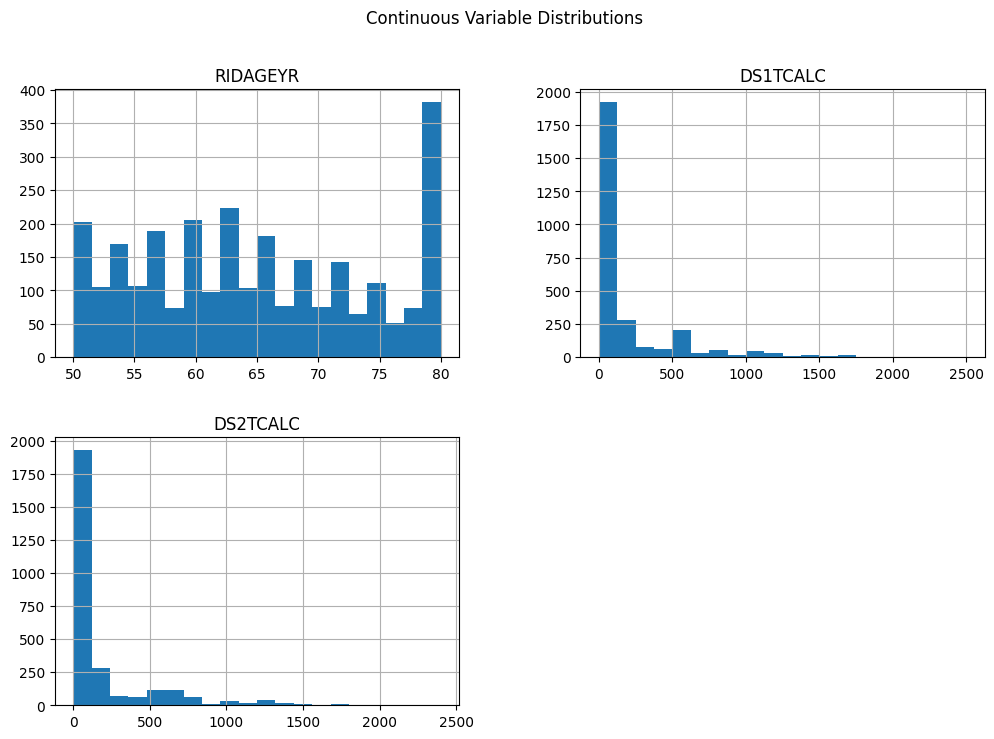

### Summary Statistics
            count        mean         std   min    5%   10%   25%   50%  \
RIDAGEYR  2780.0   64.721583    9.432026  50.0  51.0  52.0  57.0  64.0   
DS1TCALC  2780.0  170.551439  335.374750   0.0   0.0   0.0   0.0   0.0   
DS2TCALC  2780.0  170.303237  335.160980   0.0   0.0   0.0   0.0   0.0   

             75%    90%     95%     max  
RIDAGEYR   72.00   80.0   80.00    80.0  
DS1TCALC  213.25  600.0  940.50  2500.0  
DS2TCALC  212.50  600.0  933.85  2400.0  


/tmp/ipykernel_626674/2229286288.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=var, ax=axes[i//3, i%3], palette='viridis')
/tmp/ipykernel_626674/2229286288.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=var, ax=axes[i//3, i%3], palette='viridis')
/tmp/ipykernel_626674/2229286288.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=var, ax=axes[i//3, i%3], palette='viridis')
/tmp/ipykernel_626674/2229286288.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and w

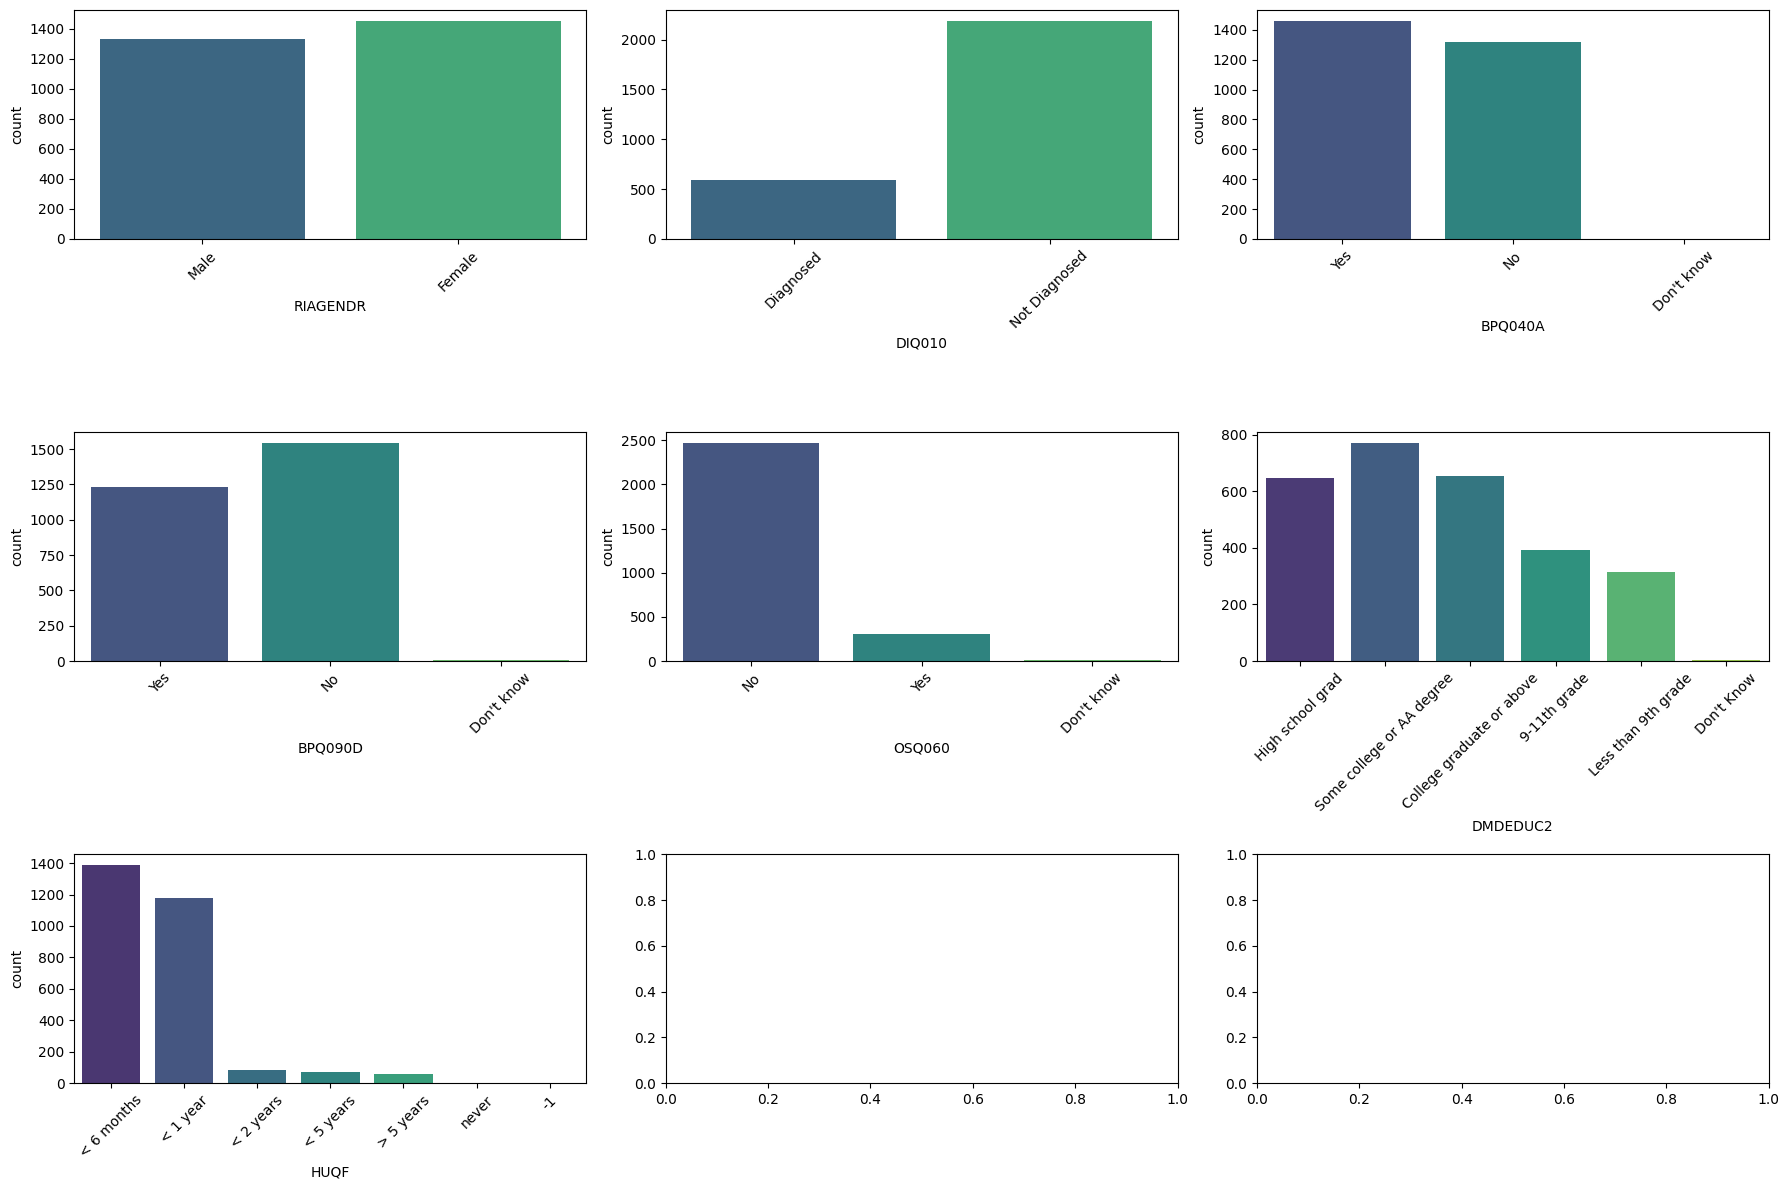

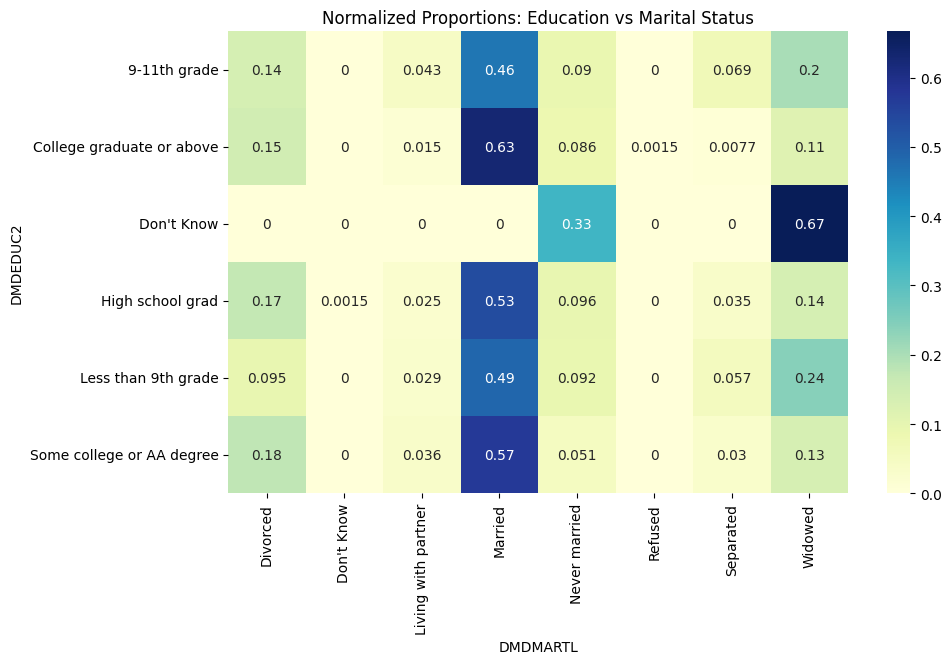

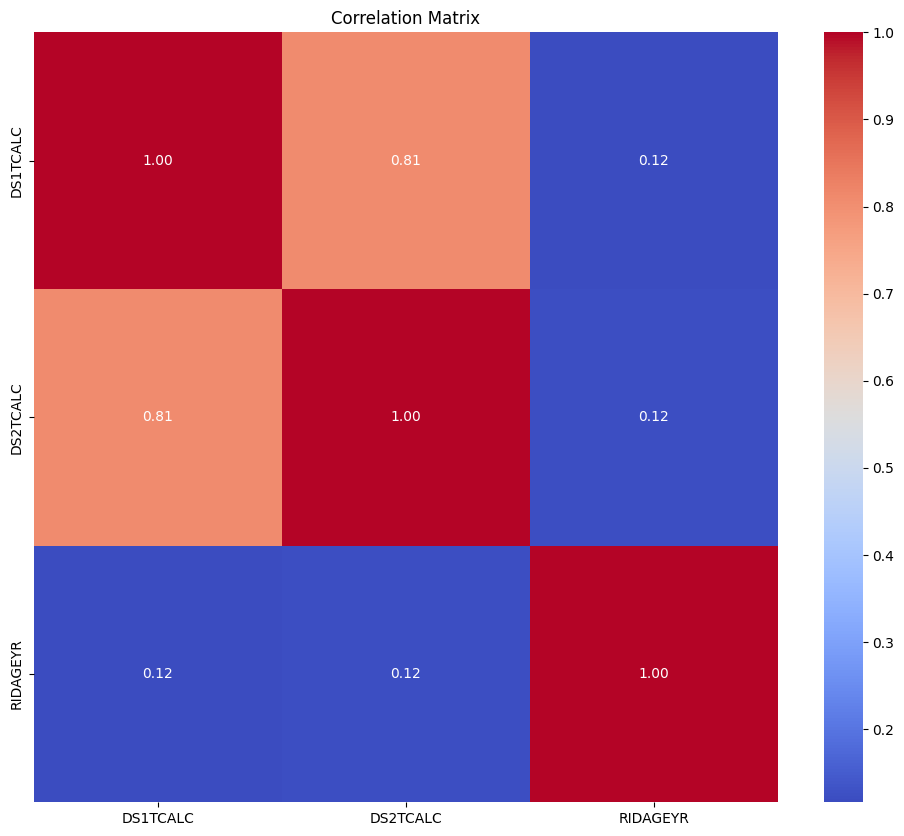

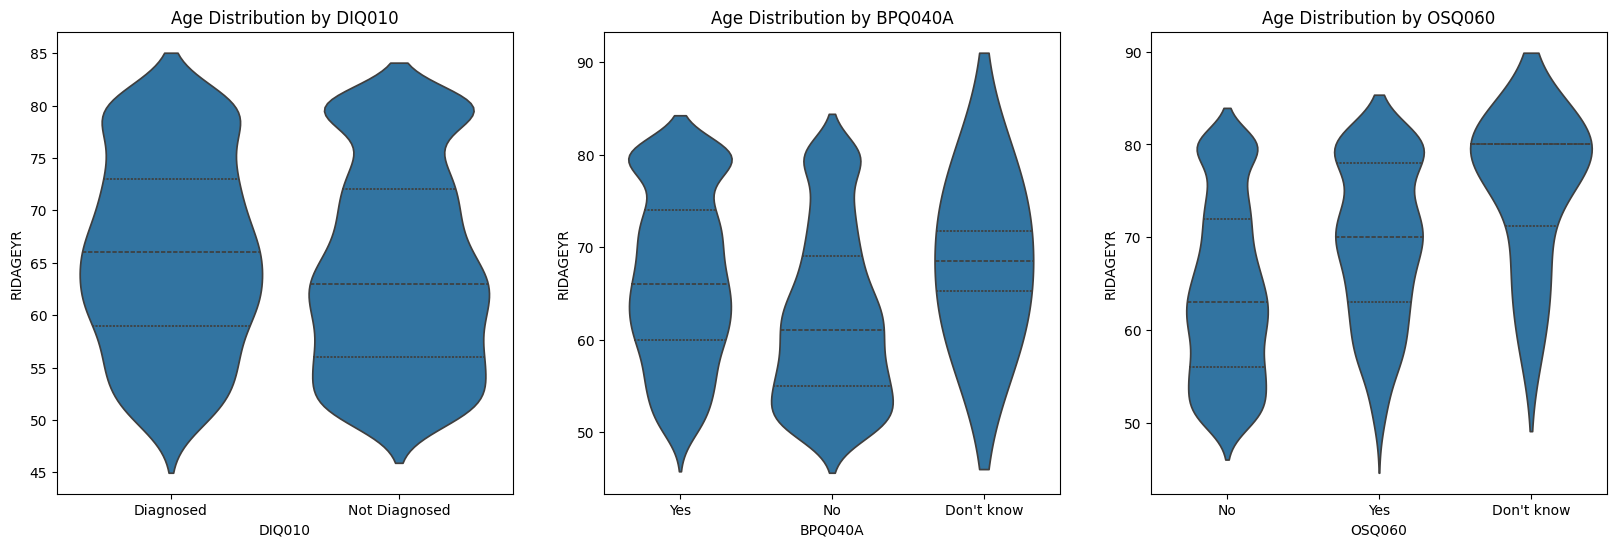

### Morbidity Prevalence by Gender
             DIQ010   BPQ040A   BPQ090D    OSQ060
RIAGENDR                                        
Female    0.203997  0.554790  0.436940  0.181943
Male      0.222724  0.492852  0.448457  0.028593


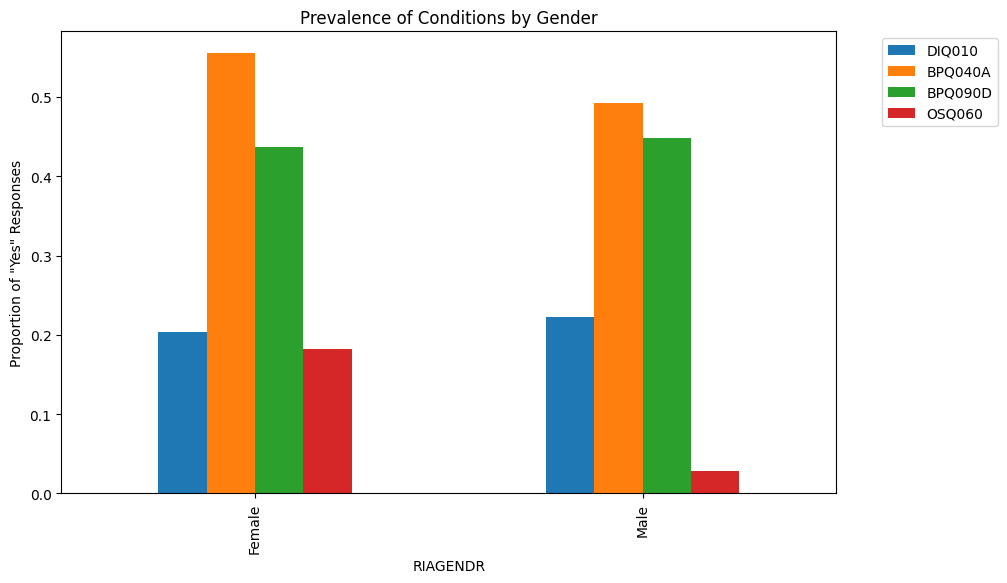

In [94]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

cont_vars = ['RIDAGEYR', 'SLD010H', 'DS1TCALC', 'DS2TCALC']
cat_vars = ['RIAGENDR', 'DIQ010', 'BPQ040A', 'BPQ090D', 'OSQ060', 'DMDEDUC2', 'HUQF']
morbidity_vars = ['DIQ010', 'BPQ040A', 'BPQ090D', 'OSQ060']

# Histograms
df[cont_vars].hist(bins=20, figsize=(12, 8), layout=(2, 2))
plt.suptitle('Continuous Variable Distributions')
plt.show()

# Summary Statistics
quantiles = [.05, .10, .25, .5, .75, .9, .95]
stats = df[cont_vars].describe(percentiles=quantiles).T
print("### Summary Statistics\n", stats)

# Bar Charts
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 12))
for i, var in enumerate(cat_vars):
    sns.countplot(data=df, x=var, ax=axes[i//3, i%3], palette='viridis')
    axes[i//3, i%3].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# Heatmaps 
ctab = pd.crosstab(df['DMDEDUC2'], df['DMDMARTL'], normalize='index')
plt.figure(figsize=(10, 6))
sns.heatmap(ctab, annot=True, cmap='YlGnBu')
plt.title('Normalized Proportions: Education vs Marital Status')
plt.show()

# Correlation Matrix (Numerical Encoding for Matrix)
plt.figure(figsize=(12, 10))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

# Violin Plots: Age vs Chronic Indicators
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
conditions = ['DIQ010', 'BPQ040A', 'OSQ060']
for i, var in enumerate(conditions):
    sns.violinplot(data=df, x=var, y='RIDAGEYR', ax=axes[i], inner="quart")
    axes[i].set_title(f'Age Distribution by {var}')
plt.show()

# Morbidity Prevalence by Gender
morbidity_by_gender = df.groupby('RIAGENDR')[morbidity_vars].apply(lambda x: ((x == 'Yes') | (x == 'Diagnosed')).mean())
print("### Morbidity Prevalence by Gender\n", morbidity_by_gender)

morbidity_by_gender.plot(kind='bar', figsize=(10, 6))
plt.title('Prevalence of Conditions by Gender')
plt.ylabel('Proportion of "Yes" Responses')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

# Data preparation

## 1 Data selection


The model must only use variables that the B2B customers have access to, otherwise it cannot run on a real scenario. When taking into account that constraint, let’s get as many vars as possible (var selection will be done later on).


2. **FACTORS**
    1. **Physical Difficulties / Impairments**
        1. DLQ010 - hearing **REMOVE/PROXY**
        2. DLQ020 - seeing  **REMOVE/PROXY**
        3. DLQ040 - concentrating, remembering, making decisions **REMOVE/PROXY**
        4. DLQ050 - walking or climbing stairs **REMOVE/PROXY**
        **Locomotion / handling difficulty**
            * PFQ061H **REMOVE**
            * PFQ061I **REMOVE**
            * PFQ061J **REMOVE**
            * PFQ061P **REMOVE**
            * PFQ054 **REMOVE**
            * PFQ059 **REMOVE**
    2. **Medications**
        1. RXDCOUNT : N° of prescribed medicine **MAINTAIN**
    3. **Mental difficulties / Impairments**
        1. Confusion or periods of diff remembering - PFQ057 **REMOVE/PROXY**
        2. Worsening of confusion or memory loss - MCQ084 **REMOVE/PROXY**
    4. **Behavioral**
        1. SLD010H - Hours of sleep **REMOVE**
    5. **Demographic**
        1. Marital status: DMDMARTL **MAINTAIN**
        2. Education level: DMDEDUC2 **MAINTAIN**
        3. Age: RIDAGEYR **MAINTAIN**
        4. Gender: RIAGENDR **MAINTAIN** 


Since we're looking to get the maximum amount of information possible, we'll choose proxy over remove for all features that present that choice. Therefore:

2. **FACTORS**
    1. **Physical Difficulties / Impairments**
        1. DLQ010 - hearing **PROXY**
        2. DLQ020 - seeing  **PROXY**
        3. DLQ040 - concentrating, remembering, making decisions **PROXY**
        4. DLQ050 - walking or climbing stairs **PROXY**
    2. **Medications**
        1. RXDCOUNT : N° of prescribed medicine **MAINTAIN**
    3. **Mental difficulties / Impairments**
        1. Confusion or periods of diff remembering - PFQ057 **PROXY**
        2. Worsening of confusion or memory loss - MCQ084 **PROXY**
    5. **Demographic**
        1. Marital status: DMDMARTL **MAINTAIN**
        2. Education level: DMDEDUC2 **MAINTAIN**
        3. Age: RIDAGEYR **MAINTAIN**
        4. Gender: RIAGENDR **MAINTAIN** 


In [2]:
selected_variables = ['SEQN', 'RIAGENDR', 'RIDAGEYR', 'DMDEDUC2', 'DMDMARTL', 'MCQ084', 'PFQ057', 'RXDCOUNT', 'DLQ050', 'DLQ040', 'DLQ020', 'DLQ010'] 

In [3]:
import pandas as pd

df = pd.read_csv('./data/clean_data.csv').drop(columns=['Unnamed: 0'])

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2780 entries, 0 to 2779
Data columns (total 31 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   BPQ040A   2780 non-null   float64
 1   BPQ050A   2780 non-null   float64
 2   BPQ090D   2780 non-null   float64
 3   BPQ100D   2780 non-null   float64
 4   OSQ060    2780 non-null   float64
 5   OSQ072    2780 non-null   float64
 6   DS1TCALC  2780 non-null   float64
 7   DS2TCALC  2780 non-null   float64
 8   DIQ050    2780 non-null   float64
 9   DIQ070    2780 non-null   float64
 10  DIQ180    2780 non-null   float64
 11  DLQ010    2780 non-null   float64
 12  DLQ020    2780 non-null   float64
 13  DLQ040    2780 non-null   float64
 14  DLQ050    2780 non-null   float64
 15  PFQ061H   2780 non-null   float64
 16  PFQ061I   2780 non-null   float64
 17  PFQ061J   2780 non-null   float64
 18  PFQ061P   2780 non-null   float64
 19  PFQ054    2780 non-null   float64
 20  PFQ059    2780 non-null   float64
 21  PF

In [5]:
df = df[selected_variables]

KeyError: "['RXDCOUNT'] not in index"

In [21]:
rxd_df = pd.read_sas('./data/RXQ_RX_H.xpt')

In [22]:
rxd_df

,SEQN,RXDUSE,RXDDRUG,RXDDRGID,RXQSEEN,RXDDAYS,RXDRSC1,RXDRSC2,RXDRSC3,RXDRSD1,RXDRSD2,RXDRSD3,RXDCOUNT
0,73557.0,1.0,b'99999',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',2.0
1,73557.0,1.0,b'INSULIN',b'd00262',2.0,1460.0,b'E11',b'',b'',b'Type 2 diabetes mellitus',b'',b'',2.0
2,73558.0,1.0,b'GABAPENTIN',b'd03182',1.0,243.0,b'G25.81',b'',b'',b'Restless legs syndrome',b'',b'',4.0
3,73558.0,1.0,b'INSULIN GLARGINE',b'd04538',1.0,365.0,b'E11',b'',b'',b'Type 2 diabetes mellitus',b'',b'',4.0
4,73558.0,1.0,b'OLMESARTAN',b'd04801',1.0,14.0,b'E11.2',b'',b'',b'Type 2 diabetes mellitus with kidney complic...,b'',b'',4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
20189,83727.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN
20190,83728.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN
20191,83729.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN
20192,83730.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN


RXD_COUNT is supposed to be the total number of prescription medications taken by a participant. 

If that is true, it should remain constant for the same SEQN

In [23]:
is_consistent = rxd_df.groupby('SEQN')['RXDCOUNT'].nunique() == 1

is_consistent.all()

print(is_consistent)

SEQN
73557.0     True
73558.0     True
73559.0     True
73560.0    False
73561.0     True
           ...  
83727.0    False
83728.0    False
83729.0    False
83730.0    False
83731.0    False
Name: RXDCOUNT, Length: 10175, dtype: bool


In [24]:
rxd_df[rxd_df['SEQN'] == 73560]

,SEQN,RXDUSE,RXDDRUG,RXDDRGID,RXQSEEN,RXDDAYS,RXDRSC1,RXDRSC2,RXDRSC3,RXDRSD1,RXDRSD2,RXDRSD3,RXDCOUNT
11,73560.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN


In [25]:
rxd_df['RXDCOUNT'].isna().sum()

np.int64(6094)

In [26]:
rxd_df['SEQN'].nunique()

10175

interesting... it could be age related, let's check

In [27]:
df_filtered = df[['RIDAGEYR', 'SEQN']]


In [28]:
rxd_filtered = pd.merge(df_filtered, rxd_df, 'left', 'SEQN')

In [29]:
rxd_filtered

,RIDAGEYR,SEQN,RXDUSE,RXDDRUG,RXDDRGID,RXQSEEN,RXDDAYS,RXDRSC1,RXDRSC2,RXDRSC3,RXDRSD1,RXDRSD2,RXDRSD3,RXDCOUNT
0,69.0,73557.0,1.0,b'99999',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',2.0
1,69.0,73557.0,1.0,b'INSULIN',b'd00262',2.0,1460.0,b'E11',b'',b'',b'Type 2 diabetes mellitus',b'',b'',2.0
2,54.0,73558.0,1.0,b'GABAPENTIN',b'd03182',1.0,243.0,b'G25.81',b'',b'',b'Restless legs syndrome',b'',b'',4.0
3,54.0,73558.0,1.0,b'INSULIN GLARGINE',b'd04538',1.0,365.0,b'E11',b'',b'',b'Type 2 diabetes mellitus',b'',b'',4.0
4,54.0,73558.0,1.0,b'OLMESARTAN',b'd04801',1.0,14.0,b'E11.2',b'',b'',b'Type 2 diabetes mellitus with kidney complic...,b'',b'',4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10595,80.0,83724.0,1.0,b'LOSARTAN',b'd03821',1.0,10950.0,b'I10',b'',b'',b'Essential (primary) hypertension',b'',b'',5.0
10596,80.0,83724.0,1.0,b'MESALAMINE',b'd01031',1.0,182.0,b'K52.9',b'',b'',"b'Noninfective gastroenteritis and colitis, un...",b'',b'',5.0
10597,80.0,83724.0,1.0,b'ROPINIROLE',b'd04215',1.0,5475.0,b'G25.81',b'M79.2',b'',b'Restless legs syndrome',"b'Neuralgia and neuritis, unspecified'",b'',5.0
10598,80.0,83724.0,1.0,b'TERAZOSIN',b'd00386',1.0,3650.0,b'I10',b'N40',b'',b'Essential (primary) hypertension',b'Enlarged prostate',b'',5.0


In [30]:
rxd_filtered['RXDCOUNT'].isna().sum()

np.int64(572)

In [31]:
rxd_filtered[rxd_filtered['RXDCOUNT'].isna()]

,RIDAGEYR,SEQN,RXDUSE,RXDDRUG,RXDDRGID,RXQSEEN,RXDDAYS,RXDRSC1,RXDRSC2,RXDRSC3,RXDRSD1,RXDRSD2,RXDRSD3,RXDCOUNT
28,65.0,73567.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN
32,50.0,73581.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN
33,58.0,73595.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN
34,57.0,73596.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN
76,54.0,73618.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10508,51.0,83634.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN
10531,56.0,83646.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN
10566,68.0,83692.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN
10585,58.0,83715.0,2.0,b'',b'',NaN,NaN,b'',b'',b'',b'',b'',b'',NaN


After researching, it seems that if a participant answers "No" to the "taken any prescriptions" questions, rxdcount goes to nan. In order to validate this hypothesis we should check RXDUSE (taken any prescription medicine in the past 30 days). If it is 2, we can replace NaN by 0

In [32]:
rxd_filtered[rxd_filtered['RXDCOUNT'].isna()]['RXDUSE'].value_counts()

RXDUSE
2.0    570
7.0      2
Name: count, dtype: int64

Confirmed, safe for zero interpolation

In [33]:
rxd_df['RXDCOUNT'] = rxd_df['RXDCOUNT'].fillna(0)

In [34]:
rxd_df['RXDCOUNT'].value_counts()

RXDCOUNT
0.0     6094
4.0     1616
3.0     1590
2.0     1472
5.0     1400
6.0     1338
1.0     1323
7.0     1204
8.0     1104
9.0      783
10.0     550
11.0     473
12.0     420
13.0     221
14.0     182
15.0     135
19.0      76
17.0      68
16.0      64
20.0      40
23.0      23
18.0      18
Name: count, dtype: int64

In [35]:
is_consistent = rxd_df.groupby('SEQN')['RXDCOUNT'].nunique() == 1
is_consistent.all()

np.True_

In [36]:
selected_cols_rxd = rxd_df[['SEQN', 'RXDCOUNT']]

In [37]:
rxd_counts = selected_cols_rxd.groupby('SEQN').first()

In [38]:
rxd_counts

,RXDCOUNT
SEQN,
73557.0,2.0
73558.0,4.0
73559.0,5.0
73560.0,0.0
73561.0,4.0
...,...
83727.0,0.0
83728.0,0.0
83729.0,0.0


In [39]:
rxd_counts = rxd_counts.reset_index()

In [40]:
rxd_counts['SEQN'].value_counts()

SEQN
73557.0    1
73558.0    1
73559.0    1
73560.0    1
73561.0    1
          ..
83727.0    1
83728.0    1
83729.0    1
83730.0    1
83731.0    1
Name: count, Length: 10175, dtype: int64

In [41]:
print(len(rxd_counts))
print(len(df))

10175
2780


In [42]:
df = pd.merge(df, rxd_counts, 'left', 'SEQN')

In [43]:
df.__len__()

2780

In [44]:
df['RXDCOUNT'].isna().sum()

np.int64(0)

In [45]:
df['RXDCOUNT'].value_counts()

RXDCOUNT
0.0     572
1.0     358
2.0     330
3.0     316
4.0     293
5.0     216
6.0     184
7.0     148
8.0     123
9.0      75
10.0     46
11.0     37
12.0     31
13.0     15
14.0     12
15.0      8
16.0      4
19.0      4
17.0      4
20.0      2
18.0      1
23.0      1
Name: count, dtype: int64

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2780 entries, 0 to 2779
Data columns (total 32 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   BPQ040A   2780 non-null   float64
 1   BPQ050A   2780 non-null   float64
 2   BPQ090D   2780 non-null   float64
 3   BPQ100D   2780 non-null   float64
 4   OSQ060    2780 non-null   float64
 5   OSQ072    2780 non-null   float64
 6   DS1TCALC  2780 non-null   float64
 7   DS2TCALC  2780 non-null   float64
 8   DIQ050    2780 non-null   float64
 9   DIQ070    2780 non-null   float64
 10  DIQ180    2780 non-null   float64
 11  DLQ010    2780 non-null   float64
 12  DLQ020    2780 non-null   float64
 13  DLQ040    2780 non-null   float64
 14  DLQ050    2780 non-null   float64
 15  PFQ061H   2780 non-null   float64
 16  PFQ061I   2780 non-null   float64
 17  PFQ061J   2780 non-null   float64
 18  PFQ061P   2780 non-null   float64
 19  PFQ054    2780 non-null   float64
 20  PFQ059    2780 non-null   float64
 21  PF

In [47]:
factors_df = df[selected_variables]

In [48]:
factors_df

,SEQN,RIAGENDR,RIDAGEYR,DMDEDUC2,DMDMARTL,MCQ084,PFQ057,RXDCOUNT,DLQ050,DLQ040,DLQ020,DLQ010
0,73557.0,1.0,69.0,3.0,4.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
1,73558.0,1.0,54.0,3.0,1.0,2.0,2.0,4.0,2.0,2.0,2.0,2.0
2,73559.0,1.0,72.0,4.0,1.0,2.0,2.0,5.0,2.0,2.0,2.0,1.0
3,73561.0,2.0,73.0,5.0,1.0,2.0,2.0,4.0,2.0,2.0,2.0,2.0
4,73562.0,1.0,56.0,4.0,3.0,2.0,2.0,7.0,1.0,2.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2775,83717.0,2.0,80.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
2776,83718.0,2.0,60.0,3.0,2.0,1.0,2.0,5.0,1.0,1.0,2.0,2.0
2777,83721.0,1.0,52.0,5.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0
2778,83723.0,1.0,61.0,2.0,1.0,2.0,2.0,0.0,2.0,2.0,2.0,2.0


In [50]:
factors_df.to_csv('./data/factors.csv', index=False)

## 2 Data cleaning

Nulls, outliers, invalid values… 

In [3]:
import pandas as pd

df = pd.read_csv('./data/factors.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2780 entries, 0 to 2779
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      2780 non-null   float64
 1   RIAGENDR  2780 non-null   float64
 2   RIDAGEYR  2780 non-null   float64
 3   DMDEDUC2  2780 non-null   float64
 4   DMDMARTL  2780 non-null   float64
 5   MCQ084    2780 non-null   float64
 6   PFQ057    2780 non-null   float64
 7   RXDCOUNT  2780 non-null   float64
 8   DLQ050    2780 non-null   float64
 9   DLQ040    2780 non-null   float64
 10  DLQ020    2780 non-null   float64
 11  DLQ010    2780 non-null   float64
dtypes: float64(12)
memory usage: 260.8 KB


Nulls are already good, let's check for invalid values

In [4]:
for col in df:
    print(df[col].value_counts())

SEQN
73557.0    1
73558.0    1
73559.0    1
73561.0    1
73562.0    1
          ..
83717.0    1
83718.0    1
83721.0    1
83723.0    1
83724.0    1
Name: count, Length: 2780, dtype: int64
RIAGENDR
2.0    1451
1.0    1329
Name: count, dtype: int64
RIDAGEYR
80.0    352
63.0    119
60.0    112
55.0    106
50.0    105
52.0    105
62.0    104
64.0    103
66.0    100
51.0     98
61.0     97
56.0     96
57.0     93
59.0     93
53.0     86
54.0     84
65.0     82
72.0     77
67.0     77
69.0     75
70.0     75
58.0     73
68.0     71
71.0     66
73.0     65
74.0     60
76.0     51
75.0     51
77.0     38
78.0     36
79.0     30
Name: count, dtype: int64
DMDEDUC2
4.0    770
5.0    653
3.0    648
2.0    391
1.0    315
9.0      3
Name: count, dtype: int64
DMDMARTL
1.0     1531
3.0      425
2.0      424
5.0      222
4.0       96
6.0       80
77.0       1
99.0       1
Name: count, dtype: int64
MCQ084
2.0    2461
1.0     318
9.0       1
Name: count, dtype: int64
PFQ057
2.0    2412
1.0     366
9.0   

Nothing out of the ordinary, we only need to handle the answers that mean "refused" or something else (codes 7 and 9)

Let's check how problematic it'd be to just remove those entries (as they seem to be low count )

In [5]:
values_be_removed = [7,9,77,99]
cols_to_be_skipped = ['RXDCOUNT', 'RIDAGEYR'] 

test_df = df.copy()

for col in test_df:
    if col in cols_to_be_skipped:
        print(f'Skipped col {col}')
    
    else:

        test_df = test_df[~(test_df[col].isin(values_be_removed))]

Skipped col RIDAGEYR
Skipped col RXDCOUNT


In [6]:
print(test_df.__len__())
print(df.__len__())

2769
2780


In [7]:
print((df.__len__() - test_df.__len__())/df.__len__())

0.003956834532374101


Lost 11 rows or 0.4% of the data. Acceptable. 

In [8]:
df = test_df

Let's check for outliers now. Actually, do we have to?

In [9]:
for col in df:
    print(df[col].value_counts())

SEQN
73557.0    1
73558.0    1
73559.0    1
73561.0    1
73562.0    1
          ..
83717.0    1
83718.0    1
83721.0    1
83723.0    1
83724.0    1
Name: count, Length: 2769, dtype: int64
RIAGENDR
2.0    1445
1.0    1324
Name: count, dtype: int64
RIDAGEYR
80.0    349
63.0    119
60.0    111
55.0    106
50.0    105
52.0    105
62.0    104
64.0    102
66.0    100
61.0     97
51.0     97
56.0     96
57.0     93
59.0     93
53.0     85
54.0     84
65.0     82
72.0     77
67.0     77
70.0     75
69.0     73
58.0     73
68.0     71
71.0     65
73.0     64
74.0     60
76.0     51
75.0     51
77.0     38
78.0     36
79.0     30
Name: count, dtype: int64
DMDEDUC2
4.0    768
5.0    651
3.0    646
2.0    391
1.0    313
Name: count, dtype: int64
DMDMARTL
1.0    1530
3.0     423
2.0     420
5.0     221
4.0      95
6.0      80
Name: count, dtype: int64
MCQ084
2.0    2456
1.0     313
Name: count, dtype: int64
PFQ057
2.0    2407
1.0     362
Name: count, dtype: int64
RXDCOUNT
0.0     569
1.0     357
2.

The only variable that is not categorical is RXDCOUNT, and there is no issue with the max value in the distribution. Let's check


(array([1.256e+03, 6.050e+02, 3.990e+02, 3.440e+02, 8.300e+01, 4.600e+01,
        2.400e+01, 5.000e+00, 6.000e+00, 1.000e+00]),
 array([ 0. ,  2.3,  4.6,  6.9,  9.2, 11.5, 13.8, 16.1, 18.4, 20.7, 23. ]),
 <BarContainer object of 10 artists>)

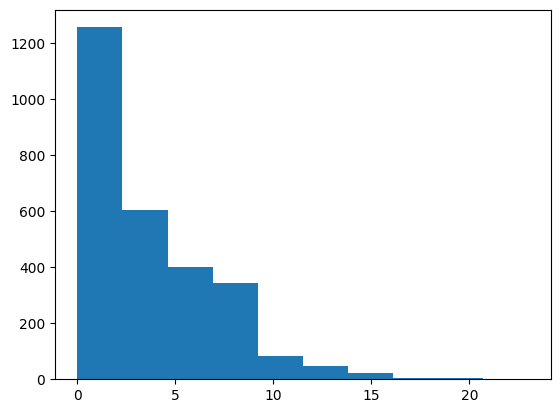

In [10]:
import matplotlib.pyplot as plt 

plt.hist(df['RXDCOUNT'])

In [11]:
max(df['RXDCOUNT'])

23.0

Alright. Let's save the changes

In [12]:
df.to_csv('./data/clean_factors.csv', index=False)

In [42]:
test = pd.read_csv('./data/clean_factors.csv')

In [43]:
test['DMDEDUC2'].value_counts()

DMDEDUC2
4.0    768
5.0    651
3.0    646
2.0    391
1.0    313
Name: count, dtype: int64

## 3 Data transformation pipeline

Variables are currently category or ordinary. Apply OHE to categoric vars, binarization to binary categoric ones, normalization to continuous ones, etc. 

In [1]:
import pandas as pd 

df = pd.read_csv('./data/clean_factors.csv')

print(df.info())
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 2769 entries, 0 to 2768
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      2769 non-null   float64
 1   RIAGENDR  2769 non-null   float64
 2   RIDAGEYR  2769 non-null   float64
 3   DMDEDUC2  2769 non-null   float64
 4   DMDMARTL  2769 non-null   float64
 5   MCQ084    2769 non-null   float64
 6   PFQ057    2769 non-null   float64
 7   RXDCOUNT  2769 non-null   float64
 8   DLQ050    2769 non-null   float64
 9   DLQ040    2769 non-null   float64
 10  DLQ020    2769 non-null   float64
 11  DLQ010    2769 non-null   float64
dtypes: float64(12)
memory usage: 259.7 KB
None


,SEQN,RIAGENDR,RIDAGEYR,DMDEDUC2,DMDMARTL,MCQ084,PFQ057,RXDCOUNT,DLQ050,DLQ040,DLQ020,DLQ010
0,73557.0,1.0,69.0,3.0,4.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
1,73558.0,1.0,54.0,3.0,1.0,2.0,2.0,4.0,2.0,2.0,2.0,2.0
2,73559.0,1.0,72.0,4.0,1.0,2.0,2.0,5.0,2.0,2.0,2.0,1.0
3,73561.0,2.0,73.0,5.0,1.0,2.0,2.0,4.0,2.0,2.0,2.0,2.0
4,73562.0,1.0,56.0,4.0,3.0,2.0,2.0,7.0,1.0,2.0,1.0,1.0


In [45]:
for col in df:
    print(df[col].value_counts())

SEQN
73557.0    1
73558.0    1
73559.0    1
73561.0    1
73562.0    1
          ..
83717.0    1
83718.0    1
83721.0    1
83723.0    1
83724.0    1
Name: count, Length: 2769, dtype: int64
RIAGENDR
2.0    1445
1.0    1324
Name: count, dtype: int64
RIDAGEYR
80.0    349
63.0    119
60.0    111
55.0    106
50.0    105
52.0    105
62.0    104
64.0    102
66.0    100
61.0     97
51.0     97
56.0     96
57.0     93
59.0     93
53.0     85
54.0     84
65.0     82
72.0     77
67.0     77
70.0     75
69.0     73
58.0     73
68.0     71
71.0     65
73.0     64
74.0     60
76.0     51
75.0     51
77.0     38
78.0     36
79.0     30
Name: count, dtype: int64
DMDEDUC2
4.0    768
5.0    651
3.0    646
2.0    391
1.0    313
Name: count, dtype: int64
DMDMARTL
1.0    1530
3.0     423
2.0     420
5.0     221
4.0      95
6.0      80
Name: count, dtype: int64
MCQ084
2.0    2456
1.0     313
Name: count, dtype: int64
PFQ057
2.0    2407
1.0     362
Name: count, dtype: int64
RXDCOUNT
0.0     569
1.0     357
2.

In [2]:
features_df = pd.DataFrame()

df.sort_index(inplace=True)

features_df['SEQN'] = df['SEQN']


In [3]:

# CATEGORIC ----------------------------------------

# BINARY VARS (set to [0,1])
# Gender
features_df['is_female'] = df['RIAGENDR'] - 1

# Difficulty hearing
features_df['diff_hearing'] = [0 if val == 2 else val for val in df['DLQ010']]

# Difficulty concentrating
features_df['diff_seeing'] = [0 if val == 2 else val for val in df['DLQ020']]

# Difficulty concentrating
features_df['diff_concentrating'] = [0 if val == 2 else val for val in df['DLQ040']]

# Difficulty walking
features_df['diff_walking'] = [0 if val == 2 else val for val in df['DLQ050']]

# Difficulty remembering
features_df['diff_remembering'] = [0 if val == 2 else val for val in df['MCQ084']]

# Confusion/memory problems
features_df['confusion'] = [0 if val == 2 else val for val in df['PFQ057']]


In [4]:
# NUMERIC ------------------------------------------------------
# DISCRETE
# Normalize age to [0:1]
features_df['norm_age'] = (df['RIDAGEYR'] - min(df['RIDAGEYR'])) / (max(df['RIDAGEYR']) - min(df['RIDAGEYR']))

# Normalize medicine ingestion count to [0:1]
features_df['norm_med_count'] = (df['RXDCOUNT'] - min(df['RXDCOUNT'])) / (max(df['RXDCOUNT']) - min(df['RXDCOUNT']))




In [6]:
from sklearn.preprocessing import OneHotEncoder
# MULTI-VALUED 
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoder.set_output(transform="pandas")

# DMDMARTL
martl_encoding = encoder.fit_transform(df[['DMDMARTL']])

In [7]:
# Drop one to avoid multicollinearity
martl_encoding.drop(columns=['DMDMARTL_1.0'], inplace=True)

In [8]:
martl_encoding.head()

,DMDMARTL_2.0,DMDMARTL_3.0,DMDMARTL_4.0,DMDMARTL_5.0,DMDMARTL_6.0
0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0


In [9]:
features_df = pd.concat([features_df, martl_encoding], axis=1)

In [10]:
features_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2769 entries, 0 to 2768
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SEQN                2769 non-null   float64
 1   is_female           2769 non-null   float64
 2   diff_hearing        2769 non-null   float64
 3   diff_seeing         2769 non-null   float64
 4   diff_concentrating  2769 non-null   float64
 5   diff_walking        2769 non-null   float64
 6   diff_remembering    2769 non-null   float64
 7   confusion           2769 non-null   float64
 8   norm_age            2769 non-null   float64
 9   norm_med_count      2769 non-null   float64
 10  DMDMARTL_2.0        2769 non-null   float64
 11  DMDMARTL_3.0        2769 non-null   float64
 12  DMDMARTL_4.0        2769 non-null   float64
 13  DMDMARTL_5.0        2769 non-null   float64
 14  DMDMARTL_6.0        2769 non-null   float64
dtypes: float64(15)
memory usage: 324.6 KB


In [11]:
features_df['education'] = df['DMDEDUC2']

In [12]:
features_df['education'].value_counts()

education
4.0    768
5.0    651
3.0    646
2.0    391
1.0    313
Name: count, dtype: int64

In [ ]:
features_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2769 entries, 0 to 2768
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SEQN                2769 non-null   float64
 1   is_female           2769 non-null   float64
 2   diff_hearing        2769 non-null   float64
 3   diff_seeing         2769 non-null   float64
 4   diff_concentrating  2769 non-null   float64
 5   diff_walking        2769 non-null   float64
 6   diff_remembering    2769 non-null   float64
 7   confusion           2769 non-null   float64
 8   norm_age            2769 non-null   float64
 9   norm_med_count      2769 non-null   float64
 10  DMDMARTL_2.0        2769 non-null   float64
 11  DMDMARTL_3.0        2769 non-null   float64
 12  DMDMARTL_4.0        2769 non-null   float64
 13  DMDMARTL_5.0        2769 non-null   float64
 14  DMDMARTL_6.0        2769 non-null   float64
 15  education           2769 non-null   float64
dtypes: float64(16)
me

In [15]:
features_df.to_csv('./data/features_df.csv')

## 4 Target feature enginnering

The goal here is to create a proxy for adherence. 

There are some ways in which we can identify that behavior with the variables in the dataset.

---

#### 1 Missing evidence of adherence 
**Description**: If a patient reports a disease / condition but does not follow prescribed treatments / drugs

**Observations**: -

#### 2 Invalid adherence report
**Description**: If a patient reports using a specific drug but it is not displayed / found (RXQ_RX_H)

**Observations**: -

#### 3 Contradictory biomarkers 
**Description**: If a patient has a condition and has the corresponding drug, but the associated biomarkers are altered 

**Observations**: Non corresponding biomarkers must be uniquely attributable to non-adherence, and not context (e.g. high pressure when speaking / nervous)

#### 4 Chronic condition, no medical visits  
**Description**: If a patient has a chronic condition that requires prescription drugs and has not consulted with a doctor for a long time or not frequently 

**Observations**: The chronic_condition -> prescription_drug and drug_needs_prescription premises must be verified  

---

#### Logical Tree

- Has condition?
- No: ?(Adherent | Remove from sample)
- Yes:
    - Condition requires drugs?
    - No: ?(Adherent | Remove from sample)
    - Yes: 
        - Is condition chronic?
        - No: Inconclusive
        - Yes:
            - Has visited doctor (in the past x | n times in the last year)?
            - No: Non adherent
            - Yes: Inconclusive 
        - Says takes drugs?
        - No: Non adherent
        - Yes:
            - Has physical drugs?
            - No: Non adherent
            - Yes:
                - Do biomarkers reflect adherence? 
                - No: Non adherent
                - Yes: Adherent 

**Notes**: 
1. This applies for each (patient, condition) pair. 
2. We'll stick to the following conditions for now: Diabetes, high blood pressure, cholesterol and ostheoporosis.


---

#### Method
For each question mapped out and its condition-dependent branches, we must define which features are to be used in the answering of it and how they answer it, i.e. define the logical statements that answer each question using the features we have 

**Question 1 - Has condition**
For each question mapped out and its condition-dependent branches, we must define which features are to be used in the answering of it and how they answer it, i.e. define the logical statements that answer each question using the features we have.

**Question 1.1 - Has Diabetes**
Source: DIQ010 (Doctor told you have diabetes)
Formal logic: df['has_diabetes'] = df['DIQ010'] == 1

**Question 1.2 - Has High Cholesterol**
Source: BPQ080 (Doctor told you have high cholesterol)
Formal logic: df['has_hchol'] = df['BPQ080'] == 1

**Question 1.3 - Has Ostheoporosis**
Source: OSQ060 (Doctor ever said you had osteoporosis)
Formal logic: df['has_osteo'] = df['OSQ060'] == 1

**Question 1.4 - Has High Blood Pressure**
Source: BPQ020 (Doctor told you have high blood pressure)
Formal logic: df['has_hbp'] = df['BPQ020'] == 1

**Question 2 - Condition requires drugs?**
Rather than assuming theoretically, we use empirical data from NHANES to check if the doctor actually prescribed medication for the patient's specific instance of the condition.

- Diabetes: YES (Implicitly, if condition progresses, but explicitly queried in DIQ050 / DIQ070)
- High blood pressure: Evaluated via BPQ040A (Doctor prescribed blood pressure medicine)
- High cholesterol: Evaluated via BPQ090D (Doctor prescribed medicine to lower cholesterol)
- Ostheoporosis: Evaluated via OSQ080 (Doctor prescribed osteoporosis pills)

**Question 3 - Is condition chronic?**

- Diabetes: YES
- High blood pressure: YES
- High cholesterol: YES
- Ostheoporosis: YES

**Question 4 - Has visited doctor (in the past x | n times in the last year)?**

It's hard to say for sure which conditions require doctor visits as a requisite for acquiring drugs. Even if we could, that's fuzzy logic.

Also, if we think about it, if the patient needs to visit the doctor to get the drug and has not been visiting the doctor, he's not going to have the drug. 

It makes more sense to use this as a feature than as a var for the target feature engineering (let the model learn if no doctor visits imply on non-adherence). 


**Question 5 - Says takes drugs?**
Evaluates the self-reported adherence against the established prescription requirement.

D: df['says_takes_d_drugs'] = (df['DIQ050'] == 1) | (df['DIQ070'] == 1) (Insulin or pills)

O: df['says_takes_o_drugs'] = df['OSQ110'] == 1

HC: df['says_takes_hc_drugs'] = df['BPQ100D'] == 1

HBP: df['says_takes_hbp_drugs'] = df['BPQ050A'] == 1

**Question 6 - Has physical drugs?**
Source: Prescription Medication Questionnaire (RXQ_RX_H).
Logic: NHANES interviewers ask to see the physical medication containers. We must cross-reference the reported therapeutic class (RXD240B - Multum Lexicon Therapeutic Class) with the condition.

HBP: Classes related to antihypertensives (e.g., ACE inhibitors, Beta blockers).

HC: Class 19 (Antihyperlipidemic agents).

D: Class 99 (Antidiabetic agents).

O: Class 17 (Metabolic bone disease agents).

**Question 7**: Eliminated due to unreliability.

#### Final Approach

Given all of those, we can simplify the logic:

- IF the patient has condition X AND has been prescribed drugs
    - IF says not takes drugs -> non adherent
    - IF says takes drugs AND NOT has physical drugs -> non adherent 

That'll be essentially it, for each condition. 


One problem that arises is the 1:n mapping regarding patient:condition. Say a patient has all conditions and is not adherent to a single condition's treatment / drug, is he therefore considered non adherent overall? 

Should we break that into each (patient,condition) pair? 

If we break that into a pair, we're now optimizing for "Given a patient has x condition, how likely is he to be non adherent to its prescribed treatment?". 

We need to handle the data accordingly by only training on patients that have a condition. 

That seems to be the best case scenario, as the way the features interact with adherence status seems to be logically dependent on the condition itself (some conditions may be more expensive, others may have non-immediate consequences leading to forgetting, etc.).

That does make sense, however, we cannot train a single logistic regression model: A linear combination of features will fail to differentiate the impact of each factor with the condition as a conditional. 

We either train a model for each condition, which is problematic due to the low amount of samples, or choose a different model that works well with conditionals. 

If we choose to change the model, we need to fullfil the criteria we set previously: 
- Interpretability
- Tractability
- Conditional internal representations

For those requirements, tree-based models seem to be the most suitable. 

Given all of that, we'll go with a significant change in how we'll do this:
- Instead of each example being a patient, each example consists of a (patient,condition) pair. 
- Instead of logistic regression, we'll use tree-based models.
- The target variable does not need to be a score or an aggregate now, only a binary vector for each example

Given that, the question now becomes how do we transform the data in order to match those requirements.

If each example consists of a (patient,condition), we need to include a feature that indicates which condition a patient has. The problem then becomes patients that have multiple conditions, since we'd only encode 1. If we use OHE (one feature for each condition), we break the scheme we elaborated above, as each example consists of a single patient. If we repeat the patient information and just change the condition we are using as target, we loose the information pertaining to how multiple conditions affect the adherence status to another target condition. 

Here's what we can do: 
One row for each patient as before, with another feature that indicates which condition the targer will be compared against, while OHE feature vectors are kept for all conditions. On that scenario, we're essentially feeding the model with: Given this patient has x,y,z conditions, how likely is he to be non adherent to the prescribed treatment of condition x? (or y or z, therefore we'll keep the patient,condition ordered pair scheme). 

#### Load and verify data

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('./data/features_df.csv')

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2769 entries, 0 to 2768
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SEQN                2769 non-null   float64
 1   is_female           2769 non-null   float64
 2   diff_hearing        2769 non-null   float64
 3   diff_seeing         2769 non-null   float64
 4   diff_concentrating  2769 non-null   float64
 5   diff_walking        2769 non-null   float64
 6   diff_remembering    2769 non-null   float64
 7   confusion           2769 non-null   float64
 8   norm_age            2769 non-null   float64
 9   norm_med_count      2769 non-null   float64
 10  DMDMARTL_2.0        2769 non-null   float64
 11  DMDMARTL_3.0        2769 non-null   float64
 12  DMDMARTL_4.0        2769 non-null   float64
 13  DMDMARTL_5.0        2769 non-null   float64
 14  DMDMARTL_6.0        2769 non-null   float64
 15  education           2769 non-null   float64
dtypes: float64(16)
me

In [ ]:
from utils import load_and_verify

diabetes_df = load_and_verify('diabetes')
blood_df = load_and_verify('blood_pres_chol')
ostheo_df = load_and_verify('ostheoporosis')

all_conditions_df = pd.merge(pd.merge(diabetes_df, blood_df, 'left', 'SEQN'), ostheo_df, 'left', 'SEQN')

all_conditions_df.info()

[diabetes] All 9 selected variables are present.
[blood_pres_chol] All 11 selected variables are present.
[ostheoporosis] All 3 selected variables are present.
<class 'pandas.DataFrame'>
RangeIndex: 9770 entries, 0 to 9769
Columns: 157 entries, SEQN to OSQ220
dtypes: float64(157)
memory usage: 11.7 MB


In [ ]:
selected_vars = 'SEQN DIQ010 BPQ080 OSQ060 BPQ020'.split()
aux_df = all_conditions_df[selected_vars]
len(aux_df)

9770

In [ ]:
print(len(df))
df = pd.merge(df, aux_df, 'left', 'SEQN')
print(len(df))

2769
2769


We first need to process the entire dataset into our new desired format (OHE conditions, one example per patient,condition pair)

In [ ]:
import numpy as np

df['has_diabetes'] =    np.where(df['DIQ010'] == 1, 1, 0)
df['has_hchol'] =       np.where(df['BPQ080'] == 1, 1, 0)
df['has_osteo'] =       np.where(df['OSQ060'] == 1, 1, 0)
df['has_hbp'] =         np.where(df['BPQ020'] == 1, 1, 0)

In [ ]:
(df['has_diabetes'] + df['has_hchol'] + df['has_osteo'] + df['has_hbp']).value_counts() 

1    895
2    839
0    604
3    395
4     36
Name: count, dtype: int64

Then we remove the patients that haveno conditions

In [ ]:
# Remove patients that have no condition
print(len(df))
df = df[(df['has_diabetes'] + df['has_hchol'] + df['has_osteo'] + df['has_hbp']) != 0]
print(len(df))

2769
2165


In [ ]:
df.info()

<class 'pandas.DataFrame'>
Index: 2165 entries, 0 to 2768
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SEQN                2165 non-null   float64
 1   is_female           2165 non-null   float64
 2   diff_hearing        2165 non-null   float64
 3   diff_seeing         2165 non-null   float64
 4   diff_concentrating  2165 non-null   float64
 5   diff_walking        2165 non-null   float64
 6   diff_remembering    2165 non-null   float64
 7   confusion           2165 non-null   float64
 8   norm_age            2165 non-null   float64
 9   norm_med_count      2165 non-null   float64
 10  DMDMARTL_2.0        2165 non-null   float64
 11  DMDMARTL_3.0        2165 non-null   float64
 12  DMDMARTL_4.0        2165 non-null   float64
 13  DMDMARTL_5.0        2165 non-null   float64
 14  DMDMARTL_6.0        2165 non-null   float64
 15  education           2165 non-null   float64
 16  DIQ010              21

In [ ]:
# Split into one dataset for each condition
with_diabetes = df[df['has_diabetes'] == 1]
with_hbp = df[df['has_hbp'] == 1]
with_hchol = df[df['has_hchol'] == 1]
with_osteo = df[df['has_osteo'] == 1]

# Set the condition feature
with_diabetes['condition'] = 'diabetes'
with_hbp['condition'] = 'hbp'
with_hchol['condition'] = 'hchol'
with_osteo['condition'] = 'osteo'

# concat into a single dataset. we should have n_rows dot_product(value_counts above), i.e. 144 + 1185 + 1678 + 895 = 3902
new_df = pd.concat([with_diabetes, with_hchol, with_hbp, with_osteo]).reset_index(drop=True)
len(new_df)

3902

Change the encoding scheme so that it becomes better for a tree format (OHE is terrible for categorical features with several values)

In [ ]:
print(df['DMDMARTL_2.0'].sum())
print(df['DMDMARTL_3.0'].sum())
print(df['DMDMARTL_4.0'].sum())
print(df['DMDMARTL_5.0'].sum())
print(df['DMDMARTL_6.0'].sum())

# df['marital'] = 2 * df['DMDMARTL_2.0'] + 3 * df['DMDMARTL_3.0'] + 4 * df['DMDMARTL_4.0'] + 5 * df['DMDMARTL_5.0'] + 6 * df['DMDMARTL_6.0']

df['marital'] = sum([(i+1)*df[f'DMDMARTL_{i+2}.0'] for i in range(5)])

df['marital'].value_counts()

367.0
305.0
78.0
156.0
54.0


marital
0.0    1205
1.0     367
2.0     305
4.0     156
3.0      78
5.0      54
Name: count, dtype: int64

In [ ]:
# Linear combination. Essentially, OHE -> "ordinal" encoding
new_df['marital'] = sum([(i+1)*new_df[f'DMDMARTL_{i+2}.0'] for i in range(5)])

new_df['marital'].value_counts()

marital
0.0    2128
1.0     725
2.0     543
4.0     271
3.0     145
5.0      90
Name: count, dtype: int64

In [ ]:
marital_cols = [f'DMDMARTL_{i+2}.0' for i in range(5)]

new_df.drop(columns=marital_cols, inplace=True)

In [ ]:
new_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3902 entries, 0 to 3901
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SEQN                3902 non-null   float64
 1   is_female           3902 non-null   float64
 2   diff_hearing        3902 non-null   float64
 3   diff_seeing         3902 non-null   float64
 4   diff_concentrating  3902 non-null   float64
 5   diff_walking        3902 non-null   float64
 6   diff_remembering    3902 non-null   float64
 7   confusion           3902 non-null   float64
 8   norm_age            3902 non-null   float64
 9   norm_med_count      3902 non-null   float64
 10  education           3902 non-null   float64
 11  DIQ010              3902 non-null   float64
 12  BPQ080              3902 non-null   float64
 13  OSQ060              3902 non-null   float64
 14  BPQ020              3902 non-null   float64
 15  has_diabetes        3902 non-null   int64  
 16  has_hchol        

In [ ]:
new_df.to_csv('./data/new_structure.csv', index=False)

### Engineer target feature

Now we can engineer the target feature according to the scheme we laid ou earlier

**Question 2 - Condition requires drugs?** Rather than assuming theoretically, we use empirical data from NHANES to check if the doctor actually prescribed medication for the patient's specific instance of the condition.  

- Diabetes: YES 
- Ostheoporosis: Evaluated via OSQ072 (Doctor prescribed)  
- High blood pressure: Evaluated via BPQ040A (Doctor prescribed blood pressure medicine) 
- High cholesterol: Evaluated via BPQ090D (Doctor prescribed medicine to lower cholesterol) 

In [1]:
import pandas as pd
from utils import load_and_verify
import numpy as np

new_df = pd.read_csv('./data/new_structure.csv')

In [2]:
aux_df = load_and_verify('ostheoporosis')[['SEQN', 'OSQ072']]
aux_df.info()

[ostheoporosis] All 3 selected variables are present.
<class 'pandas.DataFrame'>
RangeIndex: 3815 entries, 0 to 3814
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEQN    3815 non-null   float64
 1   OSQ072  322 non-null    float64
dtypes: float64(2)
memory usage: 59.7 KB


In [3]:
aux_df2 = load_and_verify('blood_pres_chol')[['BPQ040A', 'BPQ090D', 'SEQN']]
aux_df2.info()

[blood_pres_chol] All 11 selected variables are present.
<class 'pandas.DataFrame'>
RangeIndex: 6464 entries, 0 to 6463
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   BPQ040A  2174 non-null   float64
 1   BPQ090D  4620 non-null   float64
 2   SEQN     6464 non-null   float64
dtypes: float64(3)
memory usage: 151.6 KB


In [4]:
aux_df = pd.merge(aux_df, aux_df2, 'left', 'SEQN')

In [5]:
aux_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3815 entries, 0 to 3814
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SEQN     3815 non-null   float64
 1   OSQ072   322 non-null    float64
 2   BPQ040A  1872 non-null   float64
 3   BPQ090D  3330 non-null   float64
dtypes: float64(4)
memory usage: 119.3 KB


In [6]:
new_df = pd.merge(new_df, aux_df, 'left', 'SEQN')

In [7]:
# Where condition is diabetes, prescription status is always true
new_df['has_prescription'] = -1
new_df.loc[new_df['condition'] == 'diabetes', 'has_prescription'] = 1

# Where condition is osteo, OSQ072 for detemining prescription status 
new_df.loc[(new_df['condition'] == 'osteo')&(new_df['OSQ072'] == 1), 'has_prescription'] = 1
new_df.loc[(new_df['condition'] == 'osteo')&(new_df['OSQ072'] == 2), 'has_prescription'] = 0
new_df.loc[(new_df['condition'] == 'osteo')&(new_df['OSQ072'] == 9), 'has_prescription'] = 1

# Where condition is hbp, BPQ040A for detemining prescription status 
new_df.loc[(new_df['condition'] == 'hbp')&(new_df['BPQ040A'] == 1), 'has_prescription'] = 1
new_df.loc[(new_df['condition'] == 'hbp')&(new_df['BPQ040A'] != 1), 'has_prescription'] = 0

# Where condition is hchol, BPQ090D for detemining prescription status 
new_df.loc[(new_df['condition'] == 'hchol')&(new_df['BPQ090D'] == 1), 'has_prescription'] = 1
new_df.loc[(new_df['condition'] == 'hchol')&(new_df['BPQ090D'] != 1), 'has_prescription'] = 0


In [8]:
new_df['condition'].value_counts()

condition
hbp         1568
hchol       1446
diabetes     589
osteo        299
Name: count, dtype: int64

In [9]:
new_df['has_prescription'].value_counts()

has_prescription
1    3295
0     607
Name: count, dtype: int64

In [10]:

# We cannot evaluate or train on patients that have no prescriptions. Adherence is not a thing in that case, we'd just consume capacity of our model for it to learn that has_prescription = 0 -> adherence.
new_df = new_df[new_df['has_prescription'] == 1]

In [11]:
new_df['has_prescription'].value_counts()

new_df.drop(columns=['has_prescription'], inplace=True)

In [12]:
new_df

,SEQN,is_female,diff_hearing,diff_seeing,diff_concentrating,diff_walking,diff_remembering,confusion,norm_age,norm_med_count,...,BPQ020,has_diabetes,has_hchol,has_osteo,has_hbp,condition,marital,OSQ072,BPQ040A,BPQ090D
0,73557.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.633333,0.086957,...,1.0,1,1,0,1,diabetes,3.0,NaN,1.0,1.0
1,73558.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.133333,0.173913,...,1.0,1,1,0,1,diabetes,0.0,NaN,2.0,1.0
2,73559.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.733333,0.217391,...,1.0,1,1,1,1,diabetes,0.0,2.0,1.0,1.0
3,73571.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.866667,0.130435,...,1.0,1,1,0,1,diabetes,0.0,NaN,1.0,1.0
4,73615.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.500000,0.608696,...,1.0,1,1,0,1,diabetes,1.0,NaN,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3894,83505.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.666667,0.217391,...,1.0,0,1,1,1,osteo,0.0,1.0,1.0,1.0
3897,83539.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.766667,0.173913,...,1.0,1,1,1,1,osteo,4.0,1.0,1.0,1.0
3898,83584.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.200000,0.304348,...,1.0,0,1,1,1,osteo,2.0,1.0,2.0,2.0
3900,83639.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,0.347826,...,1.0,0,1,1,1,osteo,1.0,1.0,2.0,1.0


**Question 5 - Says takes drugs?** Evaluates the self-reported adherence against the established prescription requirement.  

- D: df['says_takes_d_drugs'] = (df['DIQ050'] == 1) | (df['DIQ070'] == 1) (Insulin or pills)  
- O: df['says_takes_o_drugs'] = df['OSQ110'] == 1  
- HC: df['says_takes_hc_drugs'] = df['BPQ100D'] == 1  
- HBP: df['says_takes_hbp_drugs'] = df['BPQ050A'] == 1  

In [13]:
# Load questionnaire data
diq_df, blood_df = load_and_verify('diabetes'), load_and_verify('blood_pres_chol')

[diabetes] All 9 selected variables are present.
[blood_pres_chol] All 11 selected variables are present.


In [14]:
calc_1 = load_and_verify('dietary_sup_1')[['SEQN', 'DS1TCALC']]
calc_2 = load_and_verify('dietary_sup_2')[['SEQN', 'DS2TCALC']]

calcium_info = pd.merge(calc_1, calc_2, 'left', 'SEQN')

[dietary_sup_1] All 3 selected variables are present.
[dietary_sup_2] All 3 selected variables are present.


In [15]:
aux_df = pd.merge(pd.merge(diq_df, calcium_info, 'left', 'SEQN'), blood_df, 'left', 'SEQN')

In [16]:
selected_vars = 'SEQN DIQ050 DIQ070 BPQ100D BPQ050A DS1TCALC DS2TCALC'.split()

aux_df = aux_df[selected_vars]

In [17]:
new_df = pd.merge(new_df, aux_df, 'left', 'SEQN')

In [18]:
# Where condition is diabetes, prescription status is always true
new_df
new_df['says_takes_drugs'] = -1
print(new_df['says_takes_drugs'].value_counts(normalize=True))

new_df.loc[(new_df['condition'] == 'diabetes')&((new_df['DIQ050'] == 1) | (new_df['DIQ070'] == 1)), 'says_takes_drugs'] = 1
new_df.loc[(new_df['condition'] == 'diabetes')&((new_df['DIQ050'] != 1) & (new_df['DIQ070'] != 1)), 'says_takes_drugs'] = 0 # De Morgan
print(new_df['says_takes_drugs'].value_counts(normalize=True))

# Where condition is osteo, we'll need to take a different approach, as there is no suitable questionnaire question (only supplementation info)
new_df.loc[(new_df['condition'] == 'osteo')&((new_df['DS1TCALC'] > 0) | (new_df['DS2TCALC'] > 0)), 'says_takes_drugs'] = 1 
new_df.loc[(new_df['condition'] == 'osteo')&((new_df['DS1TCALC'] <= 0) & (new_df['DS2TCALC'] <= 0)), 'says_takes_drugs'] = 0
print(new_df['says_takes_drugs'].value_counts(normalize=True))

new_df['says_takes_drugs'] = np.where((new_df['condition'] == 'osteo')&((new_df['DS1TCALC'].isna()) & (new_df['DS2TCALC'].isna())), 0, new_df['says_takes_drugs']) 
print(new_df['says_takes_drugs'].value_counts(normalize=True))

# Where condition is hbp, BPQ040A for detemining prescription status 
new_df.loc[(new_df['condition'] == 'hbp')&(new_df['BPQ050A'] == 1), 'says_takes_drugs'] = 1
new_df.loc[(new_df['condition'] == 'hbp')&(new_df['BPQ050A'] != 1), 'says_takes_drugs'] = 0
print(new_df['says_takes_drugs'].value_counts(normalize=True))

# Where condition is hchol, BPQ090D for detemining prescription status 
new_df.loc[(new_df['condition'] == 'hchol')&(new_df['BPQ050A'] == 1), 'says_takes_drugs'] = 1
new_df.loc[(new_df['condition'] == 'hchol')&(new_df['BPQ050A'] != 1), 'says_takes_drugs'] = 0
print(new_df['says_takes_drugs'].value_counts(normalize=True))

says_takes_drugs
-1    1.0
Name: proportion, dtype: float64
says_takes_drugs
-1    0.821244
 1    0.151442
 0    0.027314
Name: proportion, dtype: float64
says_takes_drugs
-1    0.790895
 1    0.181791
 0    0.027314
Name: proportion, dtype: float64
says_takes_drugs
-1    0.768134
 1    0.181791
 0    0.050076
Name: proportion, dtype: float64
says_takes_drugs
 1    0.583005
-1    0.327466
 0    0.089530
Name: proportion, dtype: float64
says_takes_drugs
1    0.801517
0    0.198483
Name: proportion, dtype: float64


**Question 6 - Has physical drugs?** Source: Prescription Medication Questionnaire (RXQ_RX_H). Logic: NHANES 

interviewers ask to see the physical medication containers. We must cross-reference the reported therapeutic class (RXD240B - Multum Lexicon Therapeutic Class) with the condition.  

- D: Class 99 (Antidiabetic agents).  
- O: Class 17 (Metabolic bone disease agents).
- HC: Class 19 (Antihyperlipidemic agents).  
- HBP: Classes related to antihypertensives (e.g., ACE inhibitors, Beta blockers).  




In [19]:
import pandas as pd
import numpy as np
from utils import load_and_verify

rx_df = load_and_verify('prescription') 

physical_drugs_df = rx_df[rx_df['RXQSEEN'] == 1].copy()

icd_columns = ['RXDRSC1', 'RXDRSC2', 'RXDRSC3', 'RXDRSD1', 'RXDRSD2', 'RXDRSD3']
for col in icd_columns:
    if col in physical_drugs_df.columns:
        physical_drugs_df[col] = physical_drugs_df[col].apply(
            lambda x: x.decode('latin1', errors='ignore') if isinstance(x, bytes) else str(x)
        ).replace({'nan': '', 'None': ''}).str.strip()

cols_present = [col for col in icd_columns if col in physical_drugs_df.columns]
physical_drugs_df['all_reasons'] = physical_drugs_df[cols_present].agg(' '.join, axis=1)

conditions_regex = {
    'diabetes': r'E0[89]|E1[013]|250',
    'hbp': r'I1[0-5]|401',
    'hchol': r'E78|272',
    'osteo': r'M8[0-2]|733'
}

for condition, pattern in conditions_regex.items():
    physical_drugs_df[f'is_drug_{condition}'] = physical_drugs_df['all_reasons'].str.contains(pattern, regex=True).astype(int)

patient_physical_drugs = physical_drugs_df.groupby('SEQN').agg({
    'is_drug_diabetes': 'max',
    'is_drug_hbp': 'max',
    'is_drug_hchol': 'max',
    'is_drug_osteo': 'max'
}).reset_index()

[prescription] All 2 selected variables are present.


In [20]:
patient_physical_drugs

,SEQN,is_drug_diabetes,is_drug_hbp,is_drug_hchol,is_drug_osteo
0,73558.0,1,0,1,0
1,73559.0,1,1,1,0
2,73561.0,0,1,0,0
3,73564.0,0,0,0,0
4,73566.0,0,0,0,0
...,...,...,...,...,...
3654,83712.0,0,1,1,0
3655,83716.0,0,0,0,0
3656,83717.0,0,1,0,0
3657,83721.0,0,0,0,0


In [21]:
patient_physical_drugs['SEQN'].value_counts()

SEQN
73558.0    1
73559.0    1
73561.0    1
73564.0    1
73566.0    1
          ..
83712.0    1
83716.0    1
83717.0    1
83721.0    1
83724.0    1
Name: count, Length: 3659, dtype: int64

In [22]:
print(len(patient_physical_drugs))
print(len(new_df))

3659
3295


In [23]:
print(pd.merge(new_df, patient_physical_drugs, 'left', 'SEQN')['is_drug_diabetes'].isna().sum())
print(pd.merge(new_df, patient_physical_drugs, 'left', 'SEQN')['is_drug_hchol'].isna().sum())
print(pd.merge(new_df, patient_physical_drugs, 'left', 'SEQN')['is_drug_hbp'].isna().sum())
print(pd.merge(new_df, patient_physical_drugs, 'left', 'SEQN')['is_drug_osteo'].isna().sum())

386
386
386
386


In [24]:

# Executa o Left Join com o dataframe principal de pares (paciente, condição)
new_df = pd.merge(new_df, patient_physical_drugs, how='left', on='SEQN')

# Preenche instâncias nulas com 0 (pacientes sem drogas físicas correspondentes validadas)
for condition in ['diabetes', 'hbp', 'hchol', 'osteo']:
    new_df[f'is_drug_{condition}'] = new_df[f'is_drug_{condition}'].fillna(0)

# Inicializa a feature final correspondente à Questão 6
new_df['has_physical_drugs'] = 0

# Avaliação condicional atrelada à variável 'condition' estruturada na etapa anterior
new_df.loc[(new_df['condition'] == 'diabetes') & (new_df['is_drug_diabetes'] == 1), 'has_physical_drugs'] = 1
new_df.loc[(new_df['condition'] == 'hbp') & (new_df['is_drug_hbp'] == 1), 'has_physical_drugs'] = 1
new_df.loc[(new_df['condition'] == 'hchol') & (new_df['is_drug_hchol'] == 1), 'has_physical_drugs'] = 1
new_df.loc[(new_df['condition'] == 'osteo') & (new_df['is_drug_osteo'] == 1), 'has_physical_drugs'] = 1

# Exclui as variáveis matriciais intermediárias para evitar vazamento de dimensionalidade
new_df.drop(columns=['is_drug_diabetes', 'is_drug_hbp', 'is_drug_hchol', 'is_drug_osteo'], inplace=True)

print(new_df['has_physical_drugs'].value_counts(normalize=True))

has_physical_drugs
1    0.720182
0    0.279818
Name: proportion, dtype: float64


**Final logic**: 
- IF the patient has condition X AND has been prescribed drugs (Q2)  (satisfied by all rows)   
    - IF says not takes drugs (Q5) -> non adherent 
    - IF says takes drugs AND NOT has physical drugs (Q6) -> non adherent

In [25]:
# Check expected numbers for later validation
print(new_df['says_takes_drugs'].value_counts(normalize=True))

print(new_df[new_df['says_takes_drugs']==1]['has_physical_drugs'].value_counts(normalize=True))

says_takes_drugs
1    0.801517
0    0.198483
Name: proportion, dtype: float64
has_physical_drugs
1    0.793639
0    0.206361
Name: proportion, dtype: float64


~36% expected to be non adherent

In [26]:
# Our target is non-adherence!
new_df['target'] = -1

new_df.loc[new_df['says_takes_drugs'] == 0, 'target'] = 1
new_df.loc[(new_df['says_takes_drugs'] == 1) & (new_df['has_physical_drugs']==0), 'target'] = 1
new_df.loc[(new_df['says_takes_drugs'] == 1) & (new_df['has_physical_drugs']==1), 'target'] = 0

new_df['target'].value_counts(normalize=True)

target
0    0.636115
1    0.363885
Name: proportion, dtype: float64

In [27]:
new_df['target'].isna().sum()

np.int64(0)

Now let's remove everything that isn't a feature or the target

In [28]:
new_df.columns

Index(['SEQN', 'is_female', 'diff_hearing', 'diff_seeing',
       'diff_concentrating', 'diff_walking', 'diff_remembering', 'confusion',
       'norm_age', 'norm_med_count', 'education', 'DIQ010', 'BPQ080', 'OSQ060',
       'BPQ020', 'has_diabetes', 'has_hchol', 'has_osteo', 'has_hbp',
       'condition', 'marital', 'OSQ072', 'BPQ040A', 'BPQ090D', 'DIQ050',
       'DIQ070', 'BPQ100D', 'BPQ050A', 'DS1TCALC', 'DS2TCALC',
       'says_takes_drugs', 'has_physical_drugs', 'target'],
      dtype='str')

In [29]:
to_drop = 'OSQ072 BPQ040A BPQ080 OSQ060 BPQ020 BPQ100D DIQ070 BPQ050A DS1TCALC DS2TCALC says_takes_drugs has_physical_drugs DIQ010 BPQ090D DIQ050'.split()
final_df = new_df.drop(columns=to_drop)
final_df.columns

Index(['SEQN', 'is_female', 'diff_hearing', 'diff_seeing',
       'diff_concentrating', 'diff_walking', 'diff_remembering', 'confusion',
       'norm_age', 'norm_med_count', 'education', 'has_diabetes', 'has_hchol',
       'has_osteo', 'has_hbp', 'condition', 'marital', 'target'],
      dtype='str')

We also want the number of medications someone uses

In [30]:
med_counts = load_and_verify('prescription')[['SEQN', 'RXDCOUNT']].groupby('SEQN').first().reset_index()

[prescription] All 2 selected variables are present.


In [31]:
med_counts

,SEQN,RXDCOUNT
0,73557.0,2.0
1,73558.0,4.0
2,73559.0,5.0
3,73560.0,NaN
4,73561.0,4.0
...,...,...
10170,83727.0,NaN
10171,83728.0,NaN
10172,83729.0,NaN
10173,83730.0,NaN


In [32]:
len(med_counts)

10175

In [33]:
final_df = pd.merge(final_df, med_counts, 'left', 'SEQN')

In [34]:
final_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3295 entries, 0 to 3294
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SEQN                3295 non-null   float64
 1   is_female           3295 non-null   float64
 2   diff_hearing        3295 non-null   float64
 3   diff_seeing         3295 non-null   float64
 4   diff_concentrating  3295 non-null   float64
 5   diff_walking        3295 non-null   float64
 6   diff_remembering    3295 non-null   float64
 7   confusion           3295 non-null   float64
 8   norm_age            3295 non-null   float64
 9   norm_med_count      3295 non-null   float64
 10  education           3295 non-null   float64
 11  has_diabetes        3295 non-null   int64  
 12  has_hchol           3295 non-null   int64  
 13  has_osteo           3295 non-null   int64  
 14  has_hbp             3295 non-null   int64  
 15  condition           3295 non-null   str    
 16  marital          

Let's check if all factors that were selected are present:

**Features**
- Hearing OK 2
- Seeing OK 3
- Concentrating, remembering, making decisions OK 4
- Walking or climbing stairs OK 5
- Number of drugs taken DUPLICATE 9 18
- Confusion or periods of diff remembering OK 7
- Memory loss OK 6
- Marital status OK 16
- Education level OK 10
- Age OK 8
- Gender OK 1

**Feature Groups**
- Present: 1,2,3,4,5,6,7,8,*9,18*, 10, 16
- conditions: 11-15
- target: 17

**Conclusion**
All good, we just need to drop norm_med_count and fill rxdcount with 0

In [35]:
final_df['RXDCOUNT'] = final_df['RXDCOUNT'].fillna(0)

In [36]:
final_df.drop(columns=['norm_med_count'],inplace=True)

In [37]:
final_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3295 entries, 0 to 3294
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SEQN                3295 non-null   float64
 1   is_female           3295 non-null   float64
 2   diff_hearing        3295 non-null   float64
 3   diff_seeing         3295 non-null   float64
 4   diff_concentrating  3295 non-null   float64
 5   diff_walking        3295 non-null   float64
 6   diff_remembering    3295 non-null   float64
 7   confusion           3295 non-null   float64
 8   norm_age            3295 non-null   float64
 9   education           3295 non-null   float64
 10  has_diabetes        3295 non-null   int64  
 11  has_hchol           3295 non-null   int64  
 12  has_osteo           3295 non-null   int64  
 13  has_hbp             3295 non-null   int64  
 14  condition           3295 non-null   str    
 15  marital             3295 non-null   float64
 16  target           

we still need to encode the condition feature

In [38]:
mapping = {
    'osteo' : 0,
    'diabetes' : -1,
    'hchol' : 1,
    'hbp' : 2
}

final_df['condition'] = [mapping[key] for key in final_df['condition']]

In [39]:
final_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3295 entries, 0 to 3294
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SEQN                3295 non-null   float64
 1   is_female           3295 non-null   float64
 2   diff_hearing        3295 non-null   float64
 3   diff_seeing         3295 non-null   float64
 4   diff_concentrating  3295 non-null   float64
 5   diff_walking        3295 non-null   float64
 6   diff_remembering    3295 non-null   float64
 7   confusion           3295 non-null   float64
 8   norm_age            3295 non-null   float64
 9   education           3295 non-null   float64
 10  has_diabetes        3295 non-null   int64  
 11  has_hchol           3295 non-null   int64  
 12  has_osteo           3295 non-null   int64  
 13  has_hbp             3295 non-null   int64  
 14  condition           3295 non-null   int64  
 15  marital             3295 non-null   float64
 16  target           

Great, let's save this.

In [40]:
final_df.to_csv('./data/final_selection_with_target.csv', index=False)


## 5 Splitting data

In [1]:
import pandas as pd 

df = pd.read_csv('./data/final_selection_with_target.csv')

In [2]:
split_percent = 0.8

target = df['target']
features = df.drop(columns=['target'])

y_train = target.iloc[:round(0.8 * len(target))]
y_test = target.iloc[round(0.8 * len(target)):]

print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

target
0    0.644158
1    0.355842
Name: proportion, dtype: float64
target
0    0.603945
1    0.396055
Name: proportion, dtype: float64


similar enough

In [3]:
X_train = features.iloc[:round(0.8 * len(features))]
X_test = features.iloc[round(0.8 * len(features)):]

In [4]:
print(len(X_train))
print(len(y_train))
print(len(X_test))
print(len(y_test))

2636
2636
659
659


In [5]:
print(X_train.info())
print(y_train.info())
print(X_test.info())
print(y_test.info())

<class 'pandas.DataFrame'>
RangeIndex: 2636 entries, 0 to 2635
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SEQN                2636 non-null   float64
 1   is_female           2636 non-null   float64
 2   diff_hearing        2636 non-null   float64
 3   diff_seeing         2636 non-null   float64
 4   diff_concentrating  2636 non-null   float64
 5   diff_walking        2636 non-null   float64
 6   diff_remembering    2636 non-null   float64
 7   confusion           2636 non-null   float64
 8   norm_age            2636 non-null   float64
 9   education           2636 non-null   float64
 10  has_diabetes        2636 non-null   int64  
 11  has_hchol           2636 non-null   int64  
 12  has_osteo           2636 non-null   int64  
 13  has_hbp             2636 non-null   int64  
 14  condition           2636 non-null   int64  
 15  marital             2636 non-null   float64
 16  RXDCOUNT         

In [6]:
X_train.to_csv('./data/final/X_train.csv', index=False)
y_train.to_csv('./data/final/y_train.csv', index=False)
X_test.to_csv('./data/final/X_test.csv', index=False)
y_test.to_csv('./data/final/y_test.csv', index=False)